## **Patient Zero: Simulating an Outbreak**
#### *Project by Harshita Nagasubramanian*

---

Patient Zero investigates infectious disease transmission and vaccination effectiveness across complex contact networks. The study starts with a deterministic, well-mixed SIR model and then uses graph theory and stochastic simulation to represent individual contacts. The network model adds a vaccinated compartment (SIRV) for the Monte Carlo intervention experiments. The populations are synthetic and the epidemiological parameters are hypothetical.

**How does network topology influence epidemic outcomes, and how effectively can network-aware vaccination strategies reduce outbreak severity?**

- Characterize deterministic epidemic dynamics and their sensitivity to initial conditions, transmission and recovery.
- Compare network structure and connectivity, and quantify stochastic variability in outbreak trajectories.
- Compare random and degree-targeted vaccination across coverage levels against matched unvaccinated baselines.
- Estimate statistical uncertainty and assess sensitivity to the way effectiveness is aggregated.

**Table of Contents**

- [Mathematical Foundations & Deterministic SIR](#notebook-mathematical-foundations-deterministic-sir)
  - [Imports & Configuration](#notebook-imports-configuration)
  - [SIR Mathematical Model](#notebook-sir-mathematical-model)
  - [Deterministic Simulation](#notebook-deterministic-simulation)
  - [Baseline Visualization](#notebook-baseline-visualization)
  - [Metrics & Validation](#notebook-metrics-validation)
  - [Deterministic Parameter Sweep](#notebook-deterministic-parameter-sweep)
- [Graph Theory & Network-Based SIR](#notebook-graph-theory-network-based-sir)
  - [Network Generation & Analysis](#notebook-network-generation-analysis)
  - [Network-Based SIR Engine](#notebook-network-based-sir-engine)
- [Interventions & Statistical Experiments](#notebook-interventions-statistical-experiments)
  - [Vaccination Strategies](#notebook-vaccination-strategies)
  - [Monte Carlo Experiments](#notebook-monte-carlo-experiments)
  - [Statistical Analysis](#notebook-statistical-analysis)
- [Visualization & Tableau](#notebook-visualization-tableau)
  - [Research Visualizations](#notebook-research-visualizations)
  - [Tableau Data Exports](#notebook-tableau-data-exports)
- [Documentation, Validation & Publication](#notebook-documentation-validation-publication)
  - [Documentation & Final Polish](#notebook-documentation-final-polish)
  - [Findings & Conclusions](#notebook-findings-conclusions)

<a name="notebook-mathematical-foundations-deterministic-sir"></a>

### **Mathematical Foundations & Deterministic SIR**

<a name="notebook-imports-configuration"></a>

##### *Imports & Configuration*

NumPy and SciPy support numerical computation, NetworkX constructs contact graphs, and pandas organizes simulation results. Matplotlib and seaborn produce research graphics, and statsmodels supplies the multiple-comparison correction. The introductory baseline uses 1,000 individuals, 1% initially infected and no initially recovered individuals. Transmission and recovery rates are 0.3 and 0.1 per day, respectively. The integration spans 100 days with 1,001 requested evaluation points. The subsequent parameter sweep and network experiments use 500 individuals.

In [162]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from itertools import product
import random
import pandas as pd
import networkx as nx
from pathlib import Path
import math
import os
import time as timer
import seaborn as sns
from statsmodels.stats.multitest import multipletests
from scipy.stats import gaussian_kde


In [4]:
#population and initial conditions
N=1000
initial_infc_pct=0.01

I0=int(N*initial_infc_pct)
R0_initial=0
S0=N-I0-R0_initial

initial_state=[S0, I0, R0_initial]

#hypothetical disease parameters
beta=0.3
gamma=0.1

#simulation period
start_day=0
end_day=100
eval_times=np.linspace(start_day, end_day, 1001)

In [5]:
#validation
assert N>0
assert all(value>=0 for value in initial_state)
assert sum(initial_state)==N
assert beta>=0
assert gamma>0
print("Baseline configuration initialized successfully")

Baseline configuration initialized successfully


<a name="notebook-sir-mathematical-model"></a>

##### *SIR Mathematical Model*

The deterministic SIR model partitions a closed, homogeneously mixing population into susceptible $S$, infected $I$ and recovered $R$ compartments. The transmission rate $\beta$ governs movement from $S$ to $I$, and the recovery rate $\gamma$ governs movement from $I$ to $R$.

$$
\frac{dS}{dt}=-\beta\frac{SI}{N}
$$

$$
\frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I
$$

$$
\frac{dR}{dt}=\gamma I
$$

The derivatives sum to zero, so $S(t)+I(t)+R(t)=N$. In an otherwise susceptible population under homogeneous mixing, the expected number of secondary infections per infectious individual is

$$
\mathcal{R}_0=\frac{\beta}{\gamma}.
$$

This ratio follows from the deterministic model's mixing assumptions. Transmission in the stochastic network model also depends on the distribution of contacts.

In [6]:
def sir_model(t,y,beta,gamma,N):
    """
    calculate the rates of change for the SIR components
    """
    S, I, R = y
    
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    
    return [dSdt, dIdt, dRdt]

In [7]:
#test cell to check derivatives at initial state
derivatives = sir_model(start_day, initial_state, beta, gamma, N)
print("Initial SIR derivatives:", derivatives)

Initial SIR derivatives: [-2.97, 1.9700000000000002, 1.0]


<a name="notebook-deterministic-simulation"></a>

##### *Deterministic Simulation*

The coupled nonlinear equations are integrated numerically with SciPy's `solve_ivp`. Its RK45 solver uses the embedded Dormand–Prince 5(4) Runge–Kutta pair to estimate local error and adapt its internal step sizes. The requested evaluation grid specifies where the solution is reported and is distinct from the internal integration steps.

In [8]:
#using RK45
solution=solve_ivp(fun=sir_model,t_span=(start_day, end_day),y0=initial_state,t_eval=eval_times,args=(beta,gamma,N),method="RK45")
assert solution.success, f"SIR integration failed: {solution.message}"

In [9]:
#simulation results
time=solution.t
susceptible,infected,recovered=solution.y

print("Solver successful:", solution.success)
print("Solver message:", solution.message)
print("Number of time points:", len(time))
print("Final population counts:")
print(f"    Susceptible: {susceptible[-1]:.2f}")
print(f"    Infected: {infected[-1]:.2f}")
print(f"    Recovered: {recovered[-1]:.2f}")

Solver successful: True
Solver message: The solver successfully reached the end of the integration interval.
Number of time points: 1001
Final population counts:
    Susceptible: 58.63
    Infected: 1.54
    Recovered: 939.83


<a name="notebook-baseline-visualization"></a>

##### *Baseline Visualization*

Fig 1, *Baseline SIR Simulation*, shows susceptible counts declining as infection spreads and recovered counts accumulating. Infections peak when the inflow from the susceptible compartment and the outflow to recovery are approximately balanced. The compartment values are continuous population quantities.

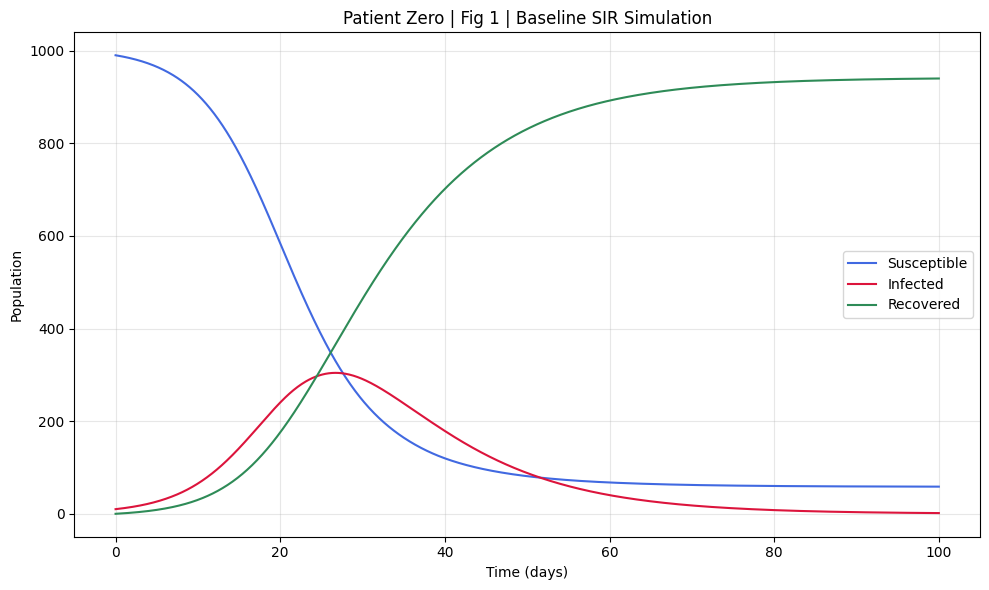

In [10]:
#deterministic SIR epidemic trajectory
fig,ax=plt.subplots(figsize=(10,6))

ax.plot(time,susceptible,label="Susceptible",color="royalblue")
ax.plot(time,infected,label="Infected",color="crimson")
ax.plot(time,recovered,label="Recovered",color="seagreen")

ax.set_title("Patient Zero | Fig 1 | Baseline SIR Simulation")
ax.set_xlabel("Time (days)")
ax.set_ylabel("Population")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

<a name="notebook-metrics-validation"></a>

##### *Metrics & Validation*

Peak infections are the maximum infected count on the requested grid, and time to peak is the corresponding day. Cumulative infections at the horizon are $N-S(t_{\mathrm{end}})$, which includes the initial infections. The attack rate divides that count by $N$.

The saved baseline peaks at 304.29 infections on day 26.7. By day 100, cumulative infections reach 941.37, for a 94.14% attack rate. The infected count is still 1.54 at the integration horizon. The numerical checks confirm population conservation within tolerance, nonnegative compartment values and successful integration.

In [11]:
#peak of epidemic
peak_index=np.argmax(infected)

peak_day=time[peak_index]
peak_infected=infected[peak_index]

#cumulative infections and attack rate
final_outbreak_size=N-susceptible[-1]
attack_rate=(final_outbreak_size/N)*100

#outbreak summary
print(f"Peak infections: {peak_infected:.2f}")
print(f"Peak day: {peak_day:.1f}")
print(f"FInal outbreak size: {final_outbreak_size:.2f}")
print(f"Attack rate: {attack_rate:.2f}%")

Peak infections: 304.29
Peak day: 26.7
FInal outbreak size: 941.37
Attack rate: 94.14%


In [12]:
#validate population conservation
total_population=susceptible+infected+recovered
population_conserved=np.allclose(total_population,N,atol=1e-6)
nonnegative_populations=np.all(solution.y>-1e-8)

solver_successful=solution.success

print(f"Population conserved: {population_conserved}")
print(f"Nonnegative populations: {nonnegative_populations}")
print(f"Solver successful: {solver_successful}")

assert population_conserved, "Population conservation failed: total population does not equal N at some time points."
assert nonnegative_populations, "Nonnegative populations failed: some population counts are negative."
assert solver_successful, f"Solver failed: {solution.message}"

Population conserved: True
Nonnegative populations: True
Solver successful: True


<a name="notebook-deterministic-parameter-sweep"></a>

##### *Deterministic Parameter Sweep*

The sweep standardizes population size at 500 and varies the initial infected proportion and both epidemiological rates.

| Parameter | Values |
|---|---|
| Population | 500 |
| Initial infected proportion | 1%, 5%, 10% |
| Transmission rate | 0.2, 0.3, 0.4 |
| Recovery rate | 0.10, 0.20, 0.25 |

The Cartesian product contains $3\times3\times3=27$ scenarios. Each row records the grid-based peak and its timing, cumulative infections at the horizon and attack rate as a percentage. The saved checks confirm successful integration and coverage of the complete parameter grid.

In [13]:
experiment_population=500
initial_infected_pct_options=[0.01,0.05,0.1]
beta_options=[0.2,0.3,0.4]
gamma_options=[0.1,0.2,0.25]

In [14]:
parameter_grid=list(product(initial_infected_pct_options,beta_options,gamma_options))
expected_scenarios=len(initial_infected_pct_options)*len(beta_options)*len(gamma_options)

assert len(parameter_grid)==expected_scenarios

print(f"Total deterministic scenarios: {len(parameter_grid)}")
print("First scenario parameters:", parameter_grid[0])
print("Last scenario parameters:", parameter_grid[-1])

Total deterministic scenarios: 27
First scenario parameters: (0.01, 0.2, 0.1)
Last scenario parameters: (0.1, 0.4, 0.25)


In [15]:
def run_sir_scenario(initial_infected_pct, beta, gamma, N=500):
    """
    Run a single deterministic SIR scenario using RK45
    """
    
    #compartment populations
    I0=int(N*initial_infected_pct)
    R0_initial=0
    S0=N-I0-R0_initial
    
    #differential equations
    solution=solve_ivp(fun=sir_model,t_span=(start_day, end_day),y0=[S0, I0, R0_initial],t_eval=eval_times,args=(beta,gamma,N),method="RK45")
    assert solution.success, solution.message
    return solution

In [16]:
#single test scenario
test_number=random.randint(0, len(parameter_grid)-1)
test_pct, test_beta, test_gamma = parameter_grid[test_number]
test_solution=run_sir_scenario(test_pct, test_beta, test_gamma, N=experiment_population)

print("Initial Infected percentage:", test_pct)
print("Beta value:", test_beta)
print("Gamma value:", test_gamma)
print()
print("Simulation successful:",test_solution.success)
print("Time points:", len(test_solution.t))
print("Initial populations:", test_solution.y[:,0])
print("Final populations:", test_solution.y[:,-1])

Initial Infected percentage: 0.1
Beta value: 0.3
Gamma value: 0.2

Simulation successful: True
Time points: 1001
Initial populations: [450.  50.   0.]
Final populations: [1.64196995e+02 1.79322265e-02 3.35785072e+02]


In [17]:
#all deterministic scenarios
scenario_results=[]

for scenario_id, (pct,beta_value,gamma_value) in enumerate(parameter_grid,start=1):
    result=run_sir_scenario(pct, beta_value, gamma_value, N=experiment_population)
    S,I,R=result.y
    
    peak_index=np.argmax(I)
    peak_infection=I[peak_index]
    peak_day=result.t[peak_index]
    final_outbreak_size=experiment_population-S[-1]
    attack_rate=(final_outbreak_size/experiment_population)*100
    
    scenario_results.append({
        "scenario_id": scenario_id,
        "population": experiment_population,
        "initial_infected_pct": pct,
        "beta": beta_value,
        "gamma": gamma_value,
        "peak_infected": peak_infection,
        "peak_day": peak_day,
        "final_outbreak_size": final_outbreak_size,
        "attack_rate": attack_rate
    })

print(f"Completed {len(scenario_results)} deterministic SIR scenarios.")

Completed 27 deterministic SIR scenarios.


In [18]:
scenarios_df=pd.DataFrame(scenario_results)
display(scenarios_df.head())
print("Dataset shape:", scenarios_df.shape)

,scenario_id,population,initial_infected_pct,beta,gamma,peak_infected,peak_day,final_outbreak_size,attack_rate
0,1,500,0.01,0.2,0.10,79.214168,43.8,392.759834,78.551967
1,2,500,0.01,0.2,0.20,5.000000,0.0,60.796954,12.159391
2,3,500,0.01,0.2,0.25,5.000000,0.0,22.455974,4.491195
3,4,500,0.01,0.3,0.10,151.880486,26.6,470.152920,94.030584
4,5,500,0.01,0.3,0.20,34.899756,32.7,296.096567,59.219313


Dataset shape: (27, 9)


In [19]:
actual_combinations = set(
    scenarios_df[
        ["initial_infected_pct", "beta", "gamma"]
    ].itertuples(index=False, name=None)
)

assert actual_combinations == set(parameter_grid)
print(f"All {len(actual_combinations)} scenarios passed batch validation")

All 27 scenarios passed batch validation


<a name="notebook-graph-theory-network-based-sir"></a>

### **Graph Theory & Network-Based SIR**

<a name="notebook-network-generation-analysis"></a>

##### *Network Generation & Analysis*

**Network Generation**

In the undirected graph $G=(V,E)$, nodes represent individuals and edges represent contacts through which infection can spread. Erdős–Rényi samples edges independently, Watts–Strogatz rewires edges from a regular ring lattice, and Barabási–Albert adds nodes through preferential attachment. Each graph has 500 nodes, target average degree 8 and seed 42. The random graph uses edge probability $8/499$, the small-world graph uses rewiring probability 0.1, and the scale-free graph attaches each new node to four existing nodes. Similar average degrees help distinguish differences in contact arrangement from differences in overall contact density.

In [20]:
#shared network configuration
network_population=500
target_avg_degree=8
network_seed=42

#topology-specific parameters
random_edge_prob=target_avg_degree/(network_population-1)
small_world_rewiring=0.1
scale_free_attachment=target_avg_degree//2

In [21]:
networks={
    "Random": nx.erdos_renyi_graph(network_population,random_edge_prob,seed=network_seed),
    "Small-world": nx.watts_strogatz_graph(network_population,target_avg_degree,small_world_rewiring,seed=network_seed),
    "Scale-free": nx.barabasi_albert_graph(network_population,scale_free_attachment,seed=network_seed)
    }

In [22]:
for topology,graph in networks.items():
    print(f"topology:{topology}")
    print(f"    nodes: {graph.number_of_nodes()}")
    print(f"    edges: {graph.number_of_edges()}")
    print(f"    average degree: {2*graph.number_of_edges()/graph.number_of_nodes():.2f}")
    print()

topology:Random
    nodes: 500
    edges: 1959
    average degree: 7.84

topology:Small-world
    nodes: 500
    edges: 2000
    average degree: 8.00

topology:Scale-free
    nodes: 500
    edges: 1984
    average degree: 7.94



**Network Metrics & Analysis**

Degree counts a node's contacts, average degree summarizes connectivity across nodes, and maximum degree measures the most connected node. The mean clustering coefficient summarizes how often neighbours are linked to each other. Connected components count mutually reachable groups, and average shortest-path length measures the typical minimum number of edges between nodes. All three generated graphs are connected.

| Topology | Average degree | Maximum degree | Mean clustering | Mean shortest path |
|---|---:|---:|---:|---:|
| Random | 7.836 | 17 | 0.013 | 3.253 |
| Small-world | 8.000 | 11 | 0.490 | 4.618 |
| Scale-free | 7.936 | 95 | 0.054 | 2.931 |

The small-world realization has the most local clustering, while the scale-free realization has a prominent hub with 95 contacts. These statistics characterize the specific generated graphs.

In [23]:

#structural properties
network_metrics=[]

for topology,graph in networks.items():
    degrees=[degree for node, degree in graph.degree()]
    metrics={
        "topology": topology,
        "nodes": graph.number_of_nodes(),
        "edges": graph.number_of_edges(),
        "avg_degree": np.mean(degrees),
        "max_degree": np.max(degrees),
        "min_degree": np.min(degrees),
        "avg_clustering": nx.average_clustering(graph),
        "connected_components": nx.number_connected_components(graph)
    }

    #shortest paths
    metrics["avg_shortest_path"]=(nx.average_shortest_path_length(graph) if nx.is_connected(graph) else np.nan)
    network_metrics.append(metrics)

network_metrics_df=pd.DataFrame(network_metrics)
display(network_metrics_df.round(3))

,topology,nodes,edges,avg_degree,max_degree,min_degree,avg_clustering,connected_components,avg_shortest_path
0,Random,500,1959,7.836,17,1,0.013,1,3.253
1,Small-world,500,2000,8.000,11,6,0.490,1,4.618
2,Scale-free,500,1984,7.936,95,4,0.054,1,2.931


**Network Visualization**

Fig 2, *Network Topology Comparison*, uses a spring layout and scales node size with degree. The layout makes local clustering and hubs visible. Node positions describe graph connectivity and have no geographical interpretation.

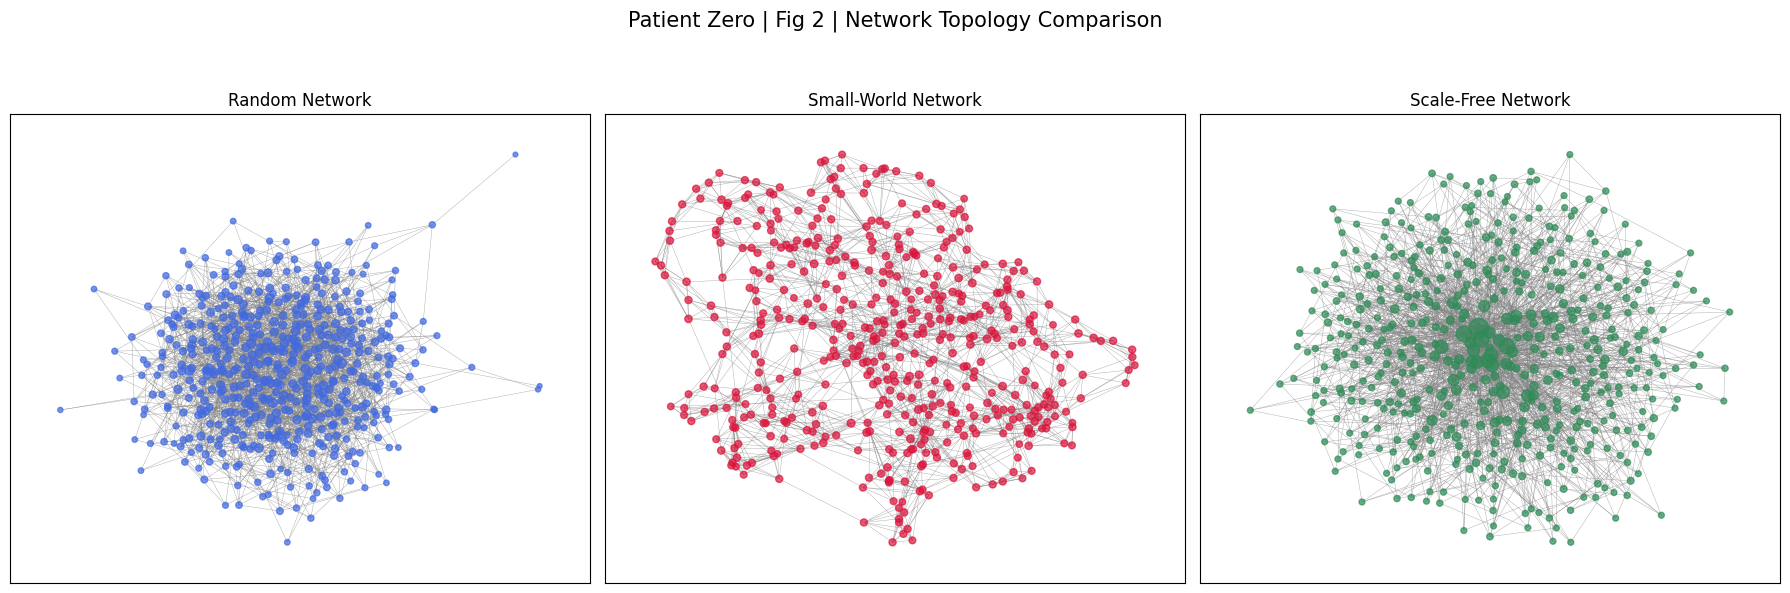

In [24]:
topology_colors = {"Random":"royalblue","Small-world":"crimson","Scale-free":"seagreen"}
fig,axes=plt.subplots(1,3,figsize=(18,6))

for ax,(topology,graph) in zip(axes,networks.items()):
    positions=nx.spring_layout(graph,seed=network_seed)
    node_sizes=[10+graph.degree(node)*2 for node in graph.nodes()]
    nx.draw_networkx(graph,pos=positions,ax=ax,node_size=node_sizes,node_color=topology_colors[topology],edge_color="gray",width=0.3,alpha=0.7,with_labels=False)
    ax.set_title(f"{topology.title()} Network",fontsize=12)

fig.suptitle("Patient Zero | Fig 2 | Network Topology Comparison",fontsize=15)
plt.tight_layout(rect=[0,0,1,0.93])
plt.show()

<a name="notebook-network-based-sir-engine"></a>

##### *Network-Based SIR Engine*

**Stochastic SIR Engine**

Each individual occupies one disease state, and initial infections are sampled uniformly without replacement. For a susceptible node with $k_I$ infected neighbours, the one-step infection probability uses the target degree $\bar{k}_{\mathrm{target}}=8$ and time step $\Delta t$.

$$
P(S\rightarrow I)=1-\exp\left(-\frac{\beta k_I\Delta t}{\bar{k}_{\mathrm{target}}}\right)
$$

An infected node recovers with probability

$$
P(I\rightarrow R)=1-\exp(-\gamma\Delta t).
$$

The simulation uses one-day steps and synchronous updates. Each transition uses the states at the start of the step, so newly infected individuals can transmit starting in the following step. An outbreak ends when no infections remain or the simulation reaches its 1,000-day cap.

In [25]:
#disease state encoding
SUSCEPTIBLE=0
INFECTED=1
RECOVERED=2

def initialize_states(graph,initial_infected_pct,rng):
    """Assign initial disease states to network individuals"""
    population=graph.number_of_nodes()
    initial_infected_count=int(population*initial_infected_pct)
    
    #an array with 500 zeros (placeholders / initial values) for 500 susceptible individuals
    #np.int8 is for saving memory since we only need 0, 1, and 2
    states=np.full(population,SUSCEPTIBLE,dtype=np.int8)
    
    infected_nodes=rng.choice(population,size=initial_infected_count,replace=False)
    states[infected_nodes]=INFECTED
    
    return states
    

In [26]:
#initial state assignment
test_rng=np.random.default_rng(network_seed)
test_graph=networks["Random"]

#test with initial_infected_pct=0.05
test_states=initialize_states(test_graph,initial_infected_pct=0.05,rng=test_rng)

print("Population:",len(test_states))
print("Susceptible:",np.sum(test_states==SUSCEPTIBLE))
print("Infected:",np.sum(test_states==INFECTED))
print("Recovered:",np.sum(test_states==RECOVERED))
print("First 20 states:",test_states[:20])

Population: 500
Susceptible: 475
Infected: 25
Recovered: 0
First 20 states: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [27]:
def stochastic_sir_step(graph,states,beta,gamma,rng,dt=1):
    """Advance the network-based SIR model by one time step"""
    #next day states for every individual
    #this is to maintain synchronous updates
    next_states=states.copy() 
    
    for node in graph.nodes():
        if states[node]==SUSCEPTIBLE:
            infected_neighbors=sum(states[neighbor]==INFECTED for neighbor in graph.neighbors(node))
            infection_prob=1-np.exp(-beta*infected_neighbors*dt/target_avg_degree)
            
            if rng.random()<infection_prob:
                next_states[node]=INFECTED
    recovery_prob=1-np.exp(-gamma*dt)
    for node in graph.nodes():
        if states[node]==INFECTED:
            if rng.random()<recovery_prob:
                next_states[node]=RECOVERED
    return next_states

In [28]:
#test one day of transmission using the same random network and initial conditions
day_0_states=test_states
day_1_states=stochastic_sir_step(test_graph,day_0_states,beta=0.3,gamma=0.1,rng=test_rng)

for day,states in [(0,day_0_states),(1,day_1_states)]:
    print(
        f"Day {day}: "
        f"Susceptible: {np.sum(states==SUSCEPTIBLE)}, "
        f"Infected: {np.sum(states==INFECTED)}, "
        f"Recovered: {np.sum(states==RECOVERED)}"
    )


Day 0: Susceptible: 475, Infected: 25, Recovered: 0
Day 1: Susceptible: 470, Infected: 27, Recovered: 3


In [29]:
assert len(day_1_states)==len(day_0_states)
assert np.all(np.isin(day_1_states, [SUSCEPTIBLE, INFECTED, RECOVERED]))
assert np.sum(day_1_states == SUSCEPTIBLE) <= np.sum(day_0_states == SUSCEPTIBLE)
assert np.sum(day_1_states == RECOVERED) >= np.sum(day_0_states == RECOVERED)

print("Daily state transition checks passed.")

Daily state transition checks passed.


In [30]:
#full outbreak simulation
def run_stochastic_sir(graph,initial_infected_pct,beta,gamma,max_days=1000,seed=42):
    """Simulate a stochastic SIR outbreak in a contact network"""
    rng=np.random.default_rng(seed)
    states=initialize_states(graph,initial_infected_pct,rng)
    history=[]
    
    for day in range(max_days+1):
        history.append({
            "day": day,
            "susceptible": np.sum(states==SUSCEPTIBLE),
            "infected": np.sum(states==INFECTED),
            "recovered": np.sum(states==RECOVERED)
        })
        
        if np.sum(states==INFECTED)==0:
            break
        
        if day==max_days:
            break
        
        states=stochastic_sir_step(graph,states,beta,gamma,rng)
    return pd.DataFrame(history)

In [31]:
test_outbreak=run_stochastic_sir(test_graph,initial_infected_pct=0.05,beta=0.3,gamma=0.1,max_days=1000,seed=network_seed)

display(test_outbreak.head())
display(test_outbreak.tail())

print("Dataset shape:", test_outbreak.shape)
print("Peak infected:", test_outbreak["infected"].max())
print("Peak day:", test_outbreak.loc[test_outbreak["infected"].idxmax(),"day"])
print("Final outbreak size:", test_outbreak["recovered"].iloc[-1])

,day,susceptible,infected,recovered
0,0,475,25,0
1,1,470,27,3
2,2,460,34,6
3,3,452,40,8
4,4,445,45,10


,day,susceptible,infected,recovered
112,112,75,1,424
113,113,75,1,424
114,114,75,1,424
115,115,75,1,424
116,116,75,0,425


Dataset shape: (117, 4)
Peak infected: 140
Peak day: 25
Final outbreak size: 425


**Outbreak Simulation Across Network Topologies**

The preliminary runs hold initial infection, transmission and recovery parameters constant across graphs. In Fig 3, *Stochastic SIR Across Network Topologies*, the small-world run has the largest final outbreak (447 infections), while the scale-free run has the highest peak (145 simultaneous infections). These are individual stochastic realizations and motivate comparisons across repeated runs.

In [32]:
outbreak_results={}

for topology,graph in networks.items():
    outbreak_results[topology]=run_stochastic_sir(graph=graph,initial_infected_pct=0.05,beta=0.3,gamma=0.1,max_days=1000,seed=network_seed)
    result=outbreak_results[topology]
    
    print(f"{topology}:")
    print(f"    Outbreak duration: {result['day'].iloc[-1]} days")
    print(f"    Peak infected: {result['infected'].max()}")
    print(f"    Final outbreak size: {graph.number_of_nodes()-result['susceptible'].iloc[-1]}")
    print()

Random:
    Outbreak duration: 116 days
    Peak infected: 140
    Final outbreak size: 425

Small-world:
    Outbreak duration: 110 days
    Peak infected: 121
    Final outbreak size: 447

Scale-free:
    Outbreak duration: 100 days
    Peak infected: 145
    Final outbreak size: 414



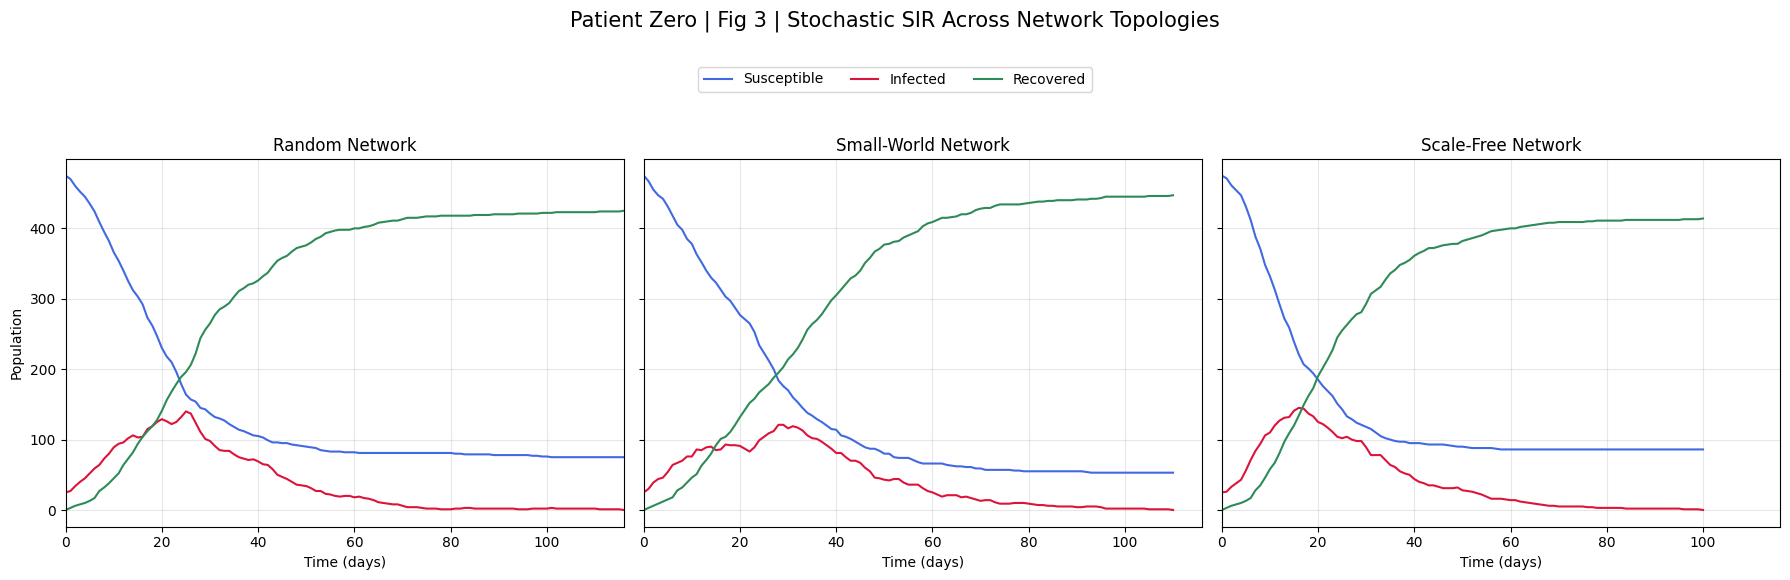

In [33]:
#let's visualize
fig,axes=plt.subplots(1,3,figsize=(18,5),sharey=True)

for ax,(topology,result) in zip(axes,outbreak_results.items()):
    ax.plot(result['day'],result['susceptible'],label="Susceptible",color="royalblue")
    ax.plot(result['day'],result['infected'],label="Infected",color="crimson")
    ax.plot(result['day'],result['recovered'],label="Recovered",color="seagreen")
    ax.set_title(f"{topology.title()} Network")
    ax.set_xlabel("Time (days)")
    ax.grid(alpha=0.3)
    
axes[0].set_ylabel("Population")

for ax in axes:
    ax.set_xlim(0,max(result['day'].iloc[-1] for result in outbreak_results.values()))

fig.legend(*axes[0].get_legend_handles_labels(),loc='upper center',ncol=3,bbox_to_anchor=(0.5,1.05))
fig.suptitle("Patient Zero | Fig 3 | Stochastic SIR Across Network Topologies",y=1.15,fontsize=15)

plt.tight_layout()
plt.show()

**Stochastic Variability**

Random initial infections and transition draws can change outbreak timing and size under identical parameters. Each topology is simulated ten times. The infected trajectories are aligned at day zero and padded with zeros after extinction to the longest duration within each topology. Fig 4, *Stochastic Variability Across Network Topologies*, plots the individual trajectories alongside their daily mean, which includes extinct runs in the denominator.

In [34]:
variability_results={}
set_seed=10

for topology,graph in networks.items():
    variability_results[topology]={}
    print(f"{topology} Network:")
    for seed in range(set_seed):
        variability_results[topology][seed]=run_stochastic_sir(graph=graph,initial_infected_pct=0.05,beta=0.3,gamma=0.1,max_days=1000,seed=seed)

    for seed,result in variability_results[topology].items():
        print(f"    Seed {seed+1}: Peak = {result['infected'].max()}  |  Duration = {result['day'].iloc[-1]}  |  Final size = {500-result['susceptible'].iloc[-1]}")
    print()

Random Network:
    Seed 1: Peak = 127  |  Duration = 98  |  Final size = 431
    Seed 2: Peak = 133  |  Duration = 106  |  Final size = 419
    Seed 3: Peak = 129  |  Duration = 94  |  Final size = 426
    Seed 4: Peak = 128  |  Duration = 111  |  Final size = 427
    Seed 5: Peak = 140  |  Duration = 99  |  Final size = 436
    Seed 6: Peak = 157  |  Duration = 79  |  Final size = 430
    Seed 7: Peak = 126  |  Duration = 84  |  Final size = 439
    Seed 8: Peak = 112  |  Duration = 102  |  Final size = 445
    Seed 9: Peak = 139  |  Duration = 103  |  Final size = 450
    Seed 10: Peak = 141  |  Duration = 112  |  Final size = 418

Small-world Network:
    Seed 1: Peak = 110  |  Duration = 97  |  Final size = 392
    Seed 2: Peak = 95  |  Duration = 117  |  Final size = 418
    Seed 3: Peak = 110  |  Duration = 140  |  Final size = 400
    Seed 4: Peak = 120  |  Duration = 151  |  Final size = 437
    Seed 5: Peak = 61  |  Duration = 150  |  Final size = 370
    Seed 6: Peak = 102  

In [35]:
assert len(variability_results)==3
assert all(len(runs)==set_seed for runs in variability_results.values())

print("All stochastic simulations stored successfully.")

All stochastic simulations stored successfully.


In [36]:
infected_trajectories_by_topology={}
mean_infected_by_topology={}

for topology,runs in variability_results.items():
    max_duration=max(result['day'].iloc[-1] for result in runs.values())
    infected_trajectories=[]
    for result in runs.values():
        infected_counts=result['infected'].to_numpy()
        padded_counts=np.pad(infected_counts,(0,max_duration+1-len(infected_counts)),constant_values=0)
        infected_trajectories.append(padded_counts)

    mean_infected=np.mean(infected_trajectories,axis=0)
    
    infected_trajectories_by_topology[topology]=infected_trajectories
    mean_infected_by_topology[topology]=mean_infected

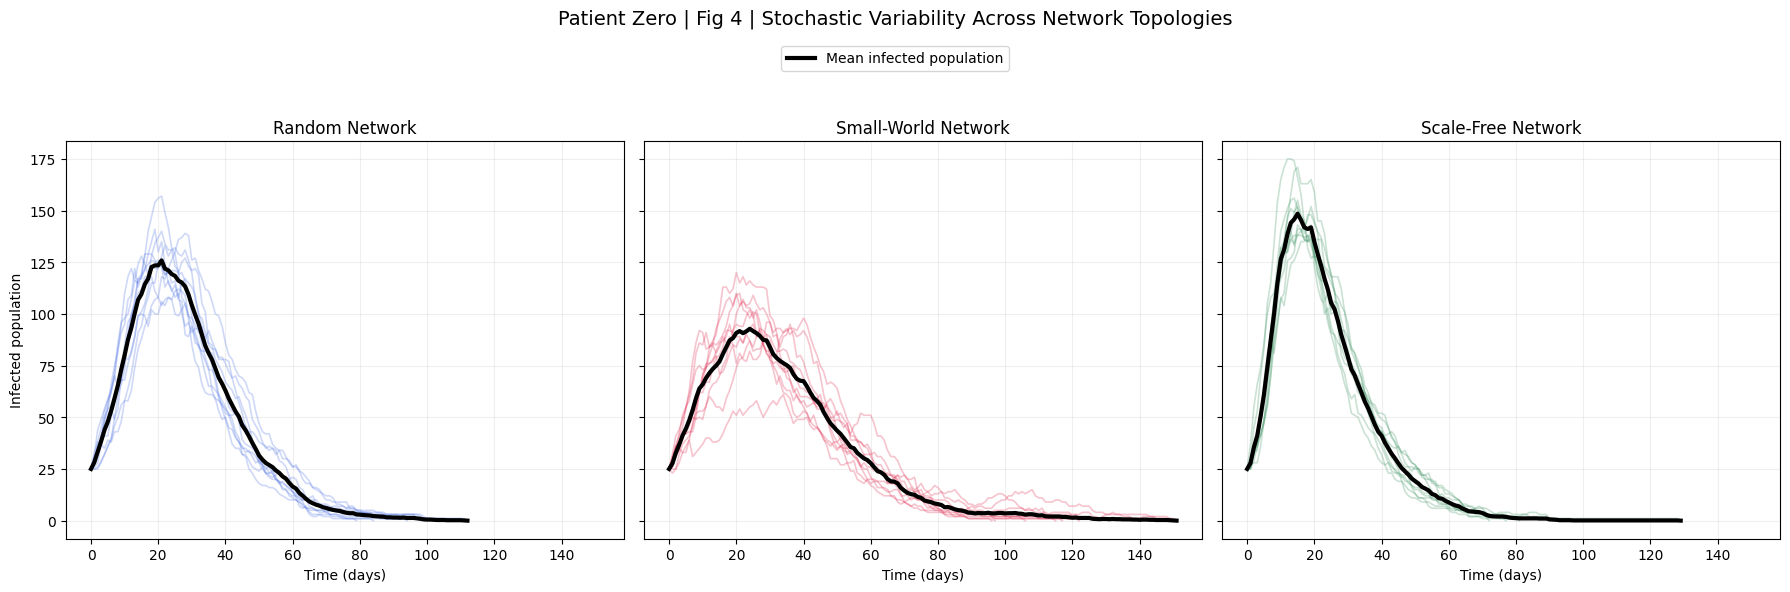

In [37]:

fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, (topology, runs) in zip(axs, variability_results.items()):
    for result in runs.values():
        ax.plot(
            result["day"],
            result["infected"],
            color=topology_colors[topology],
            alpha=0.25,
            linewidth=1.2
        )

    mean_infected = mean_infected_by_topology[topology]

    ax.plot(
        np.arange(len(mean_infected)),
        mean_infected,
        color="black",
        linewidth=3,
        label="Mean infected population"
    )

    ax.set_title(f"{topology.title()} Network")
    ax.set_xlabel("Time (days)")
    ax.grid(alpha=0.2)

axs[0].set_ylabel("Infected population")

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93)
)

fig.suptitle(
    "Patient Zero | Fig 4 | Stochastic Variability Across Network Topologies",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()


In [38]:

for topology, runs in variability_results.items():

    durations=[]
    peaks=[]
    final_sizes=[]

    for result in runs.values():
        durations.append(result["day"].iloc[-1])
        peaks.append(result["infected"].max())
        final_sizes.append(network_population-result["susceptible"].iloc[-1])

    print(f"{topology}:")
    print(f"    Average outbreak duration: {np.mean(durations):.2f} days")
    print(f"    Average peak infected: {np.mean(peaks):.2f}")
    print(f"    Average final outbreak size: {np.mean(final_sizes):.2f}")
    print()


Random:
    Average outbreak duration: 98.80 days
    Average peak infected: 133.20
    Average final outbreak size: 432.10

Small-world:
    Average outbreak duration: 122.50 days
    Average peak infected: 98.50
    Average final outbreak size: 410.40

Scale-free:
    Average outbreak duration: 91.50 days
    Average peak infected: 151.20
    Average final outbreak size: 412.20



**Validation**

The saved checks cover population conservation, valid state codes, nonnegative integer counts, nonincreasing susceptibility and nondecreasing recovery. Repeated outbreaks ended naturally before the cap, and reruns with the same seed returned identical trajectories. Edge cases cover zero initial infections and recovery without transmission. These checks assess implementation behaviour under the stated assumptions. Epidemiological calibration lies outside the study.

In [39]:

#population conservation and SIR progression
for topology,runs in variability_results.items():
    for seed,result in runs.items():
        total_population=result[["susceptible","infected","recovered"]].sum(axis=1)

        assert (total_population==network_population).all()
        
        counts=result[["susceptible","infected","recovered"]].to_numpy()

        assert np.all(counts >= 0)
        assert np.all(counts == np.floor(counts))

        assert (result["susceptible"].diff().dropna()<=0).all()
        assert (result["recovered"].diff().dropna()>=0).all()

    print(f"{topology}: All trajectories passed validation.")

print("\nTrajectory integrity validation completed successfully.")


Random: All trajectories passed validation.
Small-world: All trajectories passed validation.
Scale-free: All trajectories passed validation.

Trajectory integrity validation completed successfully.


In [40]:

#natural termination across all simulations
for topology,runs in variability_results.items():
    for seed,result in runs.items():
        assert result["infected"].iloc[-1]==0
        assert result["day"].iloc[-1]<1000

    print(f"{topology}: All outbreaks terminated naturally.")

#reproducibility
for topology,graph in networks.items():
    original=variability_results[topology][0]

    repeated=run_stochastic_sir(graph=graph,initial_infected_pct=0.05,beta=0.3,gamma=0.1,max_days=1000,seed=0)

    pd.testing.assert_frame_equal(original, repeated)

    print(f"{topology}: Reproducibility check passed.")

print("\nTermination and reproducibility validation completed.")


Random: All outbreaks terminated naturally.
Small-world: All outbreaks terminated naturally.
Scale-free: All outbreaks terminated naturally.
Random: Reproducibility check passed.
Small-world: Reproducibility check passed.
Scale-free: Reproducibility check passed.

Termination and reproducibility validation completed.


In [41]:

#edge cases
for topology,graph in networks.items():
    #zero transmission
    no_transmission = run_stochastic_sir(graph,initial_infected_pct=0.05,beta=0,gamma=0.1,seed=42)

    assert no_transmission["susceptible"].nunique()==1
    assert no_transmission["infected"].iloc[-1]==0

    #zero initial infections
    no_initial_infections = run_stochastic_sir(graph,initial_infected_pct=0,beta=0.3, gamma=0.1, seed=42)

    assert len(no_initial_infections)==1
    assert no_initial_infections["infected"].iloc[0]==0
    assert no_initial_infections["susceptible"].iloc[0]==graph.number_of_nodes()

    #recovery without transmission
    recovery_only = run_stochastic_sir(graph,initial_infected_pct=0.05,beta=0,gamma=0.5,seed=42)

    assert recovery_only["susceptible"].nunique()==1
    assert recovery_only["recovered"].iloc[-1]==round(graph.number_of_nodes() * 0.05)
    assert recovery_only["infected"].iloc[-1]==0

    print(f"{topology}: All edge-case tests passed.")

print("\nNetwork-based SIR model validation completed successfully.")


Random: All edge-case tests passed.
Small-world: All edge-case tests passed.
Scale-free: All edge-case tests passed.

Network-based SIR model validation completed successfully.


<a name="notebook-interventions-statistical-experiments"></a>

### **Interventions & Statistical Experiments**

<a name="notebook-vaccination-strategies"></a>

##### *Vaccination Strategies*

**Vaccination Configuration**

Vaccination adds a fourth compartment, with $S+I+R+V=N$. The seven configurations comprise a 0% unvaccinated baseline and random and degree-targeted vaccination at 10%, 20% and 30% coverage. Vaccination occurs before outbreak initiation and provides complete protection. Vaccinated individuals remain graph nodes. The initial infection count is calculated from the total population and assigned only among unvaccinated individuals.

In [42]:
vacc_coverage_levels=[0.1,0.2,0.3]
vacc_strategies=["Random","Degree-Targeted"]
vacc_configs=[{"strategy":"None","coverage":0.0}]

for strategy in vacc_strategies:
    for coverage in vacc_coverage_levels:
        vacc_configs.append({"strategy":strategy,"coverage":coverage})

vacc_configs

[{'strategy': 'None', 'coverage': 0.0},
 {'strategy': 'Random', 'coverage': 0.1},
 {'strategy': 'Random', 'coverage': 0.2},
 {'strategy': 'Random', 'coverage': 0.3},
 {'strategy': 'Degree-Targeted', 'coverage': 0.1},
 {'strategy': 'Degree-Targeted', 'coverage': 0.2},
 {'strategy': 'Degree-Targeted', 'coverage': 0.3}]

In [43]:
#previous population conservation: S + I + R = N
#now: S + I + R + V = N - this is to track vaccinated and naturally recovered individuals independently

vacc_rules={
    "timing":"pre-outbreak",
    "efficacy":1.0,
    "initial_infected_basis":"total_population",
    "initial_infected_eligibility":"unvaccinated",
    "preserve_network_nodes":True
}

vacc_rules

{'timing': 'pre-outbreak',
 'efficacy': 1.0,
 'initial_infected_basis': 'total_population',
 'initial_infected_eligibility': 'unvaccinated',
 'preserve_network_nodes': True}

In [44]:
#validation
assert len(vacc_configs)==7

config_pairs=[(config["strategy"],config["coverage"]) for config in vacc_configs]
assert len(config_pairs)==len(set(config_pairs))

vacc_config_df=pd.DataFrame(vacc_configs)
vacc_config_df["population"]=network_population
vacc_config_df["vaccinated count"]=(vacc_config_df["coverage"]*network_population).round().astype(int)
vacc_config_df["unvaccinated count"]=network_population-vacc_config_df["vaccinated count"]
assert vacc_config_df["vaccinated count"].tolist()==[0,50,100,150,50,100,150]

vacc_config_df

,strategy,coverage,population,vaccinated count,unvaccinated count
0,None,0.0,500,0,500
1,Random,0.1,500,50,450
2,Random,0.2,500,100,400
3,Random,0.3,500,150,350
4,Degree-Targeted,0.1,500,50,450
5,Degree-Targeted,0.2,500,100,400
6,Degree-Targeted,0.3,500,150,350


**Random Vaccination**

Vaccinated nodes are sampled uniformly without replacement using a controlled random-number generator. The checks confirm the requested counts, valid node membership, rejection of coverage outside $[0,1]$ and reproducibility under a fixed seed.

In [45]:
def select_random_vacc(graph,coverage,rng):
    if not 0<=coverage<=1:
        raise ValueError("Vaccination coverage must be between 0 and 1")
    
    population=graph.number_of_nodes()
    vacc_count=round(population*coverage)
    
    if vacc_count==0:
        return set()
    
    vacc_nodes=rng.choice(list(graph.nodes()),size=vacc_count,replace=False)
    
    return set(vacc_nodes)

In [46]:
for coverage in [0.0,0.1,0.2,0.3,1]:
    rng=np.random.default_rng(42)
    vacc=select_random_vacc(test_graph,coverage,rng)
    
    expected_count=round(test_graph.number_of_nodes()*coverage)
    
    assert len(vacc)==expected_count
    assert vacc.issubset(set(test_graph.nodes()))
    
    print(f"Coverage {coverage:.0%} | Vaccinated: {len(vacc)}")

#reproducibility
vacc_a=select_random_vacc(test_graph,0.2,np.random.default_rng(42))
vacc_b=select_random_vacc(test_graph,0.2,np.random.default_rng(42))
vacc_c=select_random_vacc(test_graph,0.2,np.random.default_rng(99))

assert vacc_a==vacc_b
assert vacc_a!=vacc_c

print("\nReproducibility checks passed")

Coverage 0% | Vaccinated: 0
Coverage 10% | Vaccinated: 50
Coverage 20% | Vaccinated: 100
Coverage 30% | Vaccinated: 150
Coverage 100% | Vaccinated: 500

Reproducibility checks passed


In [47]:
for invalid_coverage in [-0.1,1.1]:
    try:
        select_random_vacc(test_graph,invalid_coverage,np.random.default_rng(42))
    except ValueError:
        print(f"Invalid coverage {invalid_coverage}: correctly rejected")
    else:
        raise AssertionError("Invalid coverage was accepted")

Invalid coverage -0.1: correctly rejected
Invalid coverage 1.1: correctly rejected


**Degree-Targeted Vaccination**

Nodes are ranked by descending degree, with ties resolved by ascending node ID. Vaccinating the highest-ranked nodes protects individuals with many potential transmission contacts. Fig 5, *Vaccination Strategy: Network Connectivity*, compares mean vaccinated-node degree at 20% coverage. Targeting increases mean vaccinated-node degree in all three graphs, with the largest separation in the scale-free realization.

In [48]:
#degree rankings in a scale-free network
test_graph_scale_free=networks["Scale-free"]

degree_ranking=sorted(test_graph_scale_free.degree(),key=lambda item:(-item[1],item[0]))

print("Top 10 highest-degree nodes:")
for node,degree in degree_ranking[:10]:
    print(f"Node {node}: {degree} connections")

Top 10 highest-degree nodes:
Node 0: 95 connections
Node 8: 60 connections
Node 5: 59 connections
Node 7: 57 connections
Node 18: 45 connections
Node 6: 44 connections
Node 12: 43 connections
Node 10: 38 connections
Node 16: 37 connections
Node 21: 35 connections


In [49]:
def select_targeted_vacc(graph,coverage):
    if not 0<=coverage<=1:
        raise ValueError("Vaccination coverage must be between 0 and 1")
    
    population=graph.number_of_nodes()
    vacc_count=round(population*coverage)
    
    if vacc_count==0:
        return set()
    
    degree_ranking=sorted(graph.degree(),key=lambda item:(-item[1],item[0]))
    vacc_nodes={node for node,degree in degree_ranking[:vacc_count]}
    
    return vacc_nodes

In [50]:
for coverage in [0.0,0.1,0.2,0.3,1]:
    vacc=select_targeted_vacc(test_graph_scale_free,coverage)
    
    expected_count=round(test_graph.number_of_nodes()*coverage)
    
    assert len(vacc)==expected_count
    assert vacc.issubset(set(test_graph.nodes()))
    
    expected_nodes={node for node,degree in degree_ranking[:expected_count]}
    assert vacc==expected_nodes
    
    print(f"Coverage {coverage:.0%} | Vaccinated: {len(vacc)}")

print("\nDegree-ranking validation passes")

Coverage 0% | Vaccinated: 0
Coverage 10% | Vaccinated: 50
Coverage 20% | Vaccinated: 100
Coverage 30% | Vaccinated: 150
Coverage 100% | Vaccinated: 500

Degree-ranking validation passes


In [51]:
targeted_a=select_targeted_vacc(test_graph_scale_free,0.2)
targeted_b=select_targeted_vacc(test_graph_scale_free,0.2)

assert targeted_a==targeted_b

for invalid_coverage in [-0.1,1.1]:
    try:
        select_targeted_vacc(test_graph_scale_free,invalid_coverage)
    except ValueError:
        print(f"Invalid coverage {invalid_coverage}: correctly rejected")
    else:
        raise AssertionError("Invalid coverage was accepted")

print("\nReproducibility and input validation passed")

Invalid coverage -0.1: correctly rejected
Invalid coverage 1.1: correctly rejected

Reproducibility and input validation passed


In [52]:
strategy_comparison=[]
for topology,graph in networks.items():
    random_nodes=select_random_vacc(graph,0.2,np.random.default_rng(42))
    targeted_nodes=select_targeted_vacc(graph,0.2)
    
    for strategy,vacc_nodes in [("Random",random_nodes),("Degree-Targeted",targeted_nodes)]:
        avg_degree=np.mean([graph.degree(node) for node in vacc_nodes])
        strategy_comparison.append({
            "topology":topology,
            "strategy":strategy,
            "coverage":0.2,
            "vaccinated count":len(vacc_nodes),
            "average vaccinated degree":avg_degree
        })

strategy_comparison_df=pd.DataFrame(strategy_comparison)
strategy_comparison_df

,topology,strategy,coverage,vaccinated count,average vaccinated degree
0,Random,Random,0.2,100,7.59
1,Random,Degree-Targeted,0.2,100,11.88
2,Small-world,Random,0.2,100,7.97
3,Small-world,Degree-Targeted,0.2,100,9.17
4,Scale-free,Random,0.2,100,6.93
5,Scale-free,Degree-Targeted,0.2,100,18.37


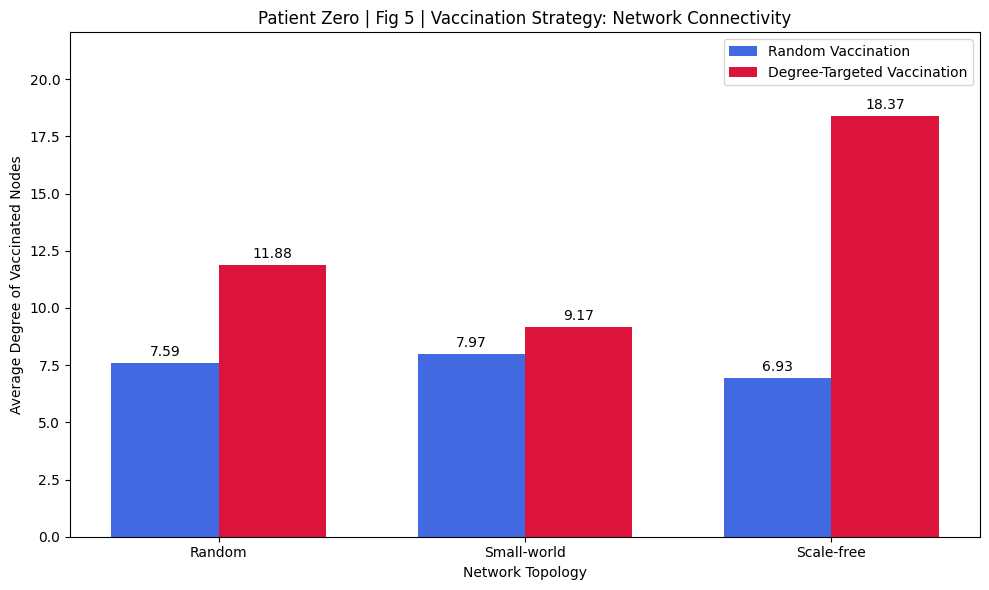

In [53]:

#visualization
vacc_colors={"Random":"royalblue","Degree-Targeted":"crimson","None":"seagreen"}

fig,ax = plt.subplots(figsize=(10,6))

topology_order=["Random","Small-world","Scale-free"]
x=np.arange(len(topology_order))
width=0.35

random_degrees=[]
targeted_degrees=[]

for topology in topology_order:
    topology_data=strategy_comparison_df[strategy_comparison_df["topology"] == topology]

    random_degrees.append(topology_data.loc[topology_data["strategy"]=="Random","average vaccinated degree"].iloc[0])
    targeted_degrees.append(topology_data.loc[topology_data["strategy"]=="Degree-Targeted","average vaccinated degree"].iloc[0])

bars_random=ax.bar(x-width/2,random_degrees,width,label="Random Vaccination", color="royalblue")

bars_targeted = ax.bar(x+width/2,targeted_degrees,width,label="Degree-Targeted Vaccination",color="crimson")

ax.bar_label(bars_random,fmt="%.2f",padding=3)
ax.bar_label(bars_targeted,fmt="%.2f",padding=3)

ax.set_xticks(x,topology_order)
ax.set_ylabel("Average Degree of Vaccinated Nodes")
ax.set_xlabel("Network Topology")
ax.set_title("Patient Zero | Fig 5 | Vaccination Strategy: Network Connectivity")
ax.legend()
ax.set_ylim(0,max(targeted_degrees)*1.2)

plt.tight_layout()
plt.show()


**Vaccination-Enabled Stochastic SIR**

The engine initializes vaccinated nodes in a protected state and applies infection and recovery transitions to susceptible and infected nodes, respectively. The graph is retained, while the set of individuals eligible for infection changes. The saved scale-free illustration in Fig 6, *SIRV Outbreak Dynamics by Vaccination Strategy*, shows 414 infections without vaccination, 277 with random vaccination and 47 with degree-targeted vaccination in the selected runs. The subsequent Monte Carlo experiment provides the replicated comparison.

In [54]:
VACCINATED=3

In [55]:
def initialize_sirv_states(graph,initial_infected_pct,vacc_nodes,rng):
    population=graph.number_of_nodes()
    initial_infected_count=round(population*initial_infected_pct)
    
    if not 0<=initial_infected_pct<=1:
        raise ValueError("Initial infected percentage must be between 0 and 1")
    if not vacc_nodes.issubset(set(graph.nodes())):
        raise ValueError("Vaccinated nodes must exist in the graph")
    
    eligible_nodes=[node for node in graph.nodes() if node not in vacc_nodes]
    
    if initial_infected_count>len(eligible_nodes):
        raise ValueError("Not enough unvaccinated nodes to initialize infections")
    
    states=np.full(population,SUSCEPTIBLE,dtype=int)
    
    for node in vacc_nodes:
        states[node]=VACCINATED
    
    if initial_infected_count>0:
        infected_nodes=rng.choice(eligible_nodes,size=initial_infected_count,replace=False)
        
        for node in infected_nodes:
            states[node]=INFECTED
    
    return states

In [56]:
#integrating V into the stochastic SIR model -> SIRV model
def run_stochastic_sirv(graph,initial_infected_pct,beta,gamma,vacc_strategy="None",vacc_coverage=0.0,max_days=1000,seed=42,rngs=None):
    if rngs is None:
        rng=np.random.default_rng(seed)
        vacc_rng=rng
        init_rng=rng
        disease_rng=rng
    else:
        vacc_rng=rngs["vaccination"]
        init_rng=rngs["initialization"]
        disease_rng=rngs["disease"]

    if vacc_strategy=="None":
        if vacc_coverage!=0:
            raise ValueError("No vaccination strategy requires zero coverage")
        vacc_nodes=set()
    elif vacc_strategy=="Random":
        vacc_nodes=select_random_vacc(graph,vacc_coverage,vacc_rng)
    elif vacc_strategy=="Degree-Targeted":
        vacc_nodes=select_targeted_vacc(graph,vacc_coverage)
    else:
        raise ValueError("Unknown vaccination strategy")
    
    states=initialize_sirv_states(graph,initial_infected_pct,vacc_nodes,init_rng)
    history=[]
    
    for day in range(max_days+1):
        history.append({
            "day":day,
            "susceptible":int(np.sum(states==SUSCEPTIBLE)),
            "infected":int(np.sum(states==INFECTED)),
            "recovered":int(np.sum(states==RECOVERED)),
            "vaccinated":int(np.sum(states==VACCINATED)),
        })
        
        if history[-1]["infected"]==0:
            break
        if day==max_days:
            break
        states=stochastic_sir_step(graph,states,beta,gamma,disease_rng)
    return pd.DataFrame(history)

In [57]:
#preliminary comparison of 3 vaccination strategies
sirv_results={}

for strategy,coverage in [("None",0.0),("Random",0.2),("Degree-Targeted",0.2)]:
    result=run_stochastic_sirv(test_graph_scale_free,0.05,0.3,0.1,strategy,coverage,1000,42)
    
    sirv_results[strategy]=result
    peak_infected=result["infected"].max()
    final_outbreak_size=result["recovered"].iloc[-1]
    duration=result["day"].iloc[-1]
    
    print(f"\n{strategy}")
    print(f"Peak infected: {peak_infected}")
    print(f"Final outbreak size: {final_outbreak_size}")
    print(f"Outbreak duration: {duration} days")
    print(f"Vaccinated: {result['vaccinated'].iloc[0]}")


None
Peak infected: 145
Final outbreak size: 414
Outbreak duration: 100 days
Vaccinated: 0

Random
Peak infected: 102
Final outbreak size: 277
Outbreak duration: 107 days
Vaccinated: 100

Degree-Targeted
Peak infected: 25
Final outbreak size: 47
Outbreak duration: 62 days
Vaccinated: 100


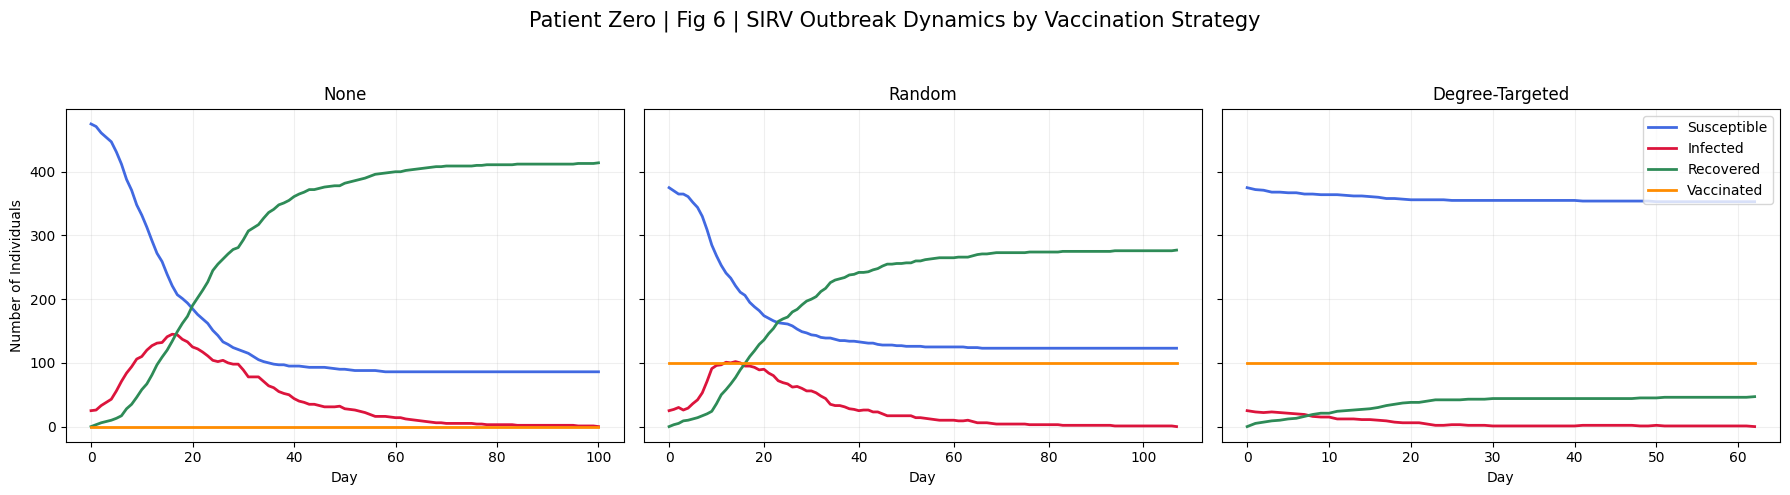

In [58]:
#visualization
fig,axes=plt.subplots(1,3,figsize=(18,5),sharey=True)

compartment_colors={"susceptible":"royalblue","infected":"crimson","recovered":"seagreen","vaccinated":"darkorange"}

for ax,(strategy,result) in zip(axes,sirv_results.items()):
    for compartment,color in compartment_colors.items():
        ax.plot(result["day"],result[compartment],label=compartment.title(),color=color,linewidth=2)

    ax.set_title(strategy)
    ax.set_xlabel("Day")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Number of Individuals")
axes[-1].legend(loc="upper right")

fig.suptitle("Patient Zero | Fig 6 | SIRV Outbreak Dynamics by Vaccination Strategy",fontsize=15)

plt.tight_layout(rect=[0,0,1,0.93])
plt.show()


**SIRV Validation & Preliminary Comparisons**

The checks verify conservation, valid compartment progression, a constant vaccinated count, extinction, reproducibility, zero initial infections and zero transmission. Fig 7, *Vaccination Impact Across Network Topologies*, illustrates variation in epidemic trajectories. A smaller outbreak can have a longer infectious tail, as seen in the preliminary random-network comparison. Repeated experiments quantify variability and support strategy comparisons.

In [59]:
for strategy,result in sirv_results.items():
    compartments=result[["susceptible", "infected", "recovered", "vaccinated"]]

    assert (compartments.sum(axis=1)==network_population).all()
    assert (compartments>=0).all().all()

    assert (result["susceptible"].diff().dropna()<=0).all()
    assert (result["recovered"].diff().dropna()>=0).all()
    assert (result["vaccinated"]==result["vaccinated"].iloc[0]).all()

    assert result["infected"].iloc[0]==25
    assert result["infected"].iloc[-1]==0

    print(f"{strategy}: all population and transition checks passed")


None: all population and transition checks passed
Random: all population and transition checks passed
Degree-Targeted: all population and transition checks passed


In [60]:
#zero initial infections
zero_infections=run_stochastic_sirv(test_graph,0.0,0.3,0.1,"Random",0.20,1000,42)

assert len(zero_infections)==1
assert zero_infections["infected"].iloc[0]==0
assert zero_infections["vaccinated"].iloc[0]==100

print("Zero initial infections: passed")


Zero initial infections: passed


In [61]:

#zero transmission validation
zero_transmission = run_stochastic_sirv(test_graph,0.05,0.0,0.5,"Degree-Targeted",0.20,1000,42)

assert zero_transmission["susceptible"].nunique()==1
assert zero_transmission["recovered"].iloc[-1]==25
assert zero_transmission["infected"].iloc[-1]==0

print("Zero transmission: passed")


Zero transmission: passed


In [62]:
#reproducibility
for strategy,coverage in [("None",0.0),("Random",0.20),("Degree-Targeted",0.20)]:
    result_a = run_stochastic_sirv(test_graph, 0.05, 0.3, 0.1,strategy,coverage,1000,42)
    result_b = run_stochastic_sirv(test_graph, 0.05, 0.3, 0.1,strategy,coverage,1000,42)

    pd.testing.assert_frame_equal(result_a,result_b)

    print(f"{strategy}: reproducibility passed")


None: reproducibility passed
Random: reproducibility passed
Degree-Targeted: reproducibility passed


In [63]:

#vaccination strategies across all network topologies
topology_sirv_results = {}
topology_comparison = []

for topology,graph in networks.items():
    topology_sirv_results[topology]={}

    for strategy, coverage in [("None",0.0),("Random",0.20),("Degree-Targeted",0.20)]:
        result=run_stochastic_sirv(graph,0.05,0.3,0.1,strategy,coverage,1000,42)
        topology_sirv_results[topology][strategy]=result

        final_infections = (result["recovered"].iloc[-1]+result["infected"].iloc[-1])

        topology_comparison.append({
            "topology":topology,
            "strategy":strategy,
            "peak_infected":result["infected"].max(),
            "final_outbreak_size":final_infections,
            "duration":result["day"].iloc[-1],
            "attack_rate":final_infections/graph.number_of_nodes()
        })

topology_comparison_df=pd.DataFrame(topology_comparison)
topology_comparison_df


,topology,strategy,peak_infected,final_outbreak_size,duration,attack_rate
0,Random,None,140,425,116,0.850
1,Random,Random,79,304,94,0.608
2,Random,Degree-Targeted,35,205,202,0.410
3,Small-world,None,121,447,110,0.894
4,Small-world,Random,51,209,147,0.418
5,Small-world,Degree-Targeted,51,227,129,0.454
6,Scale-free,None,145,414,100,0.828
7,Scale-free,Random,102,277,107,0.554
8,Scale-free,Degree-Targeted,25,47,62,0.094


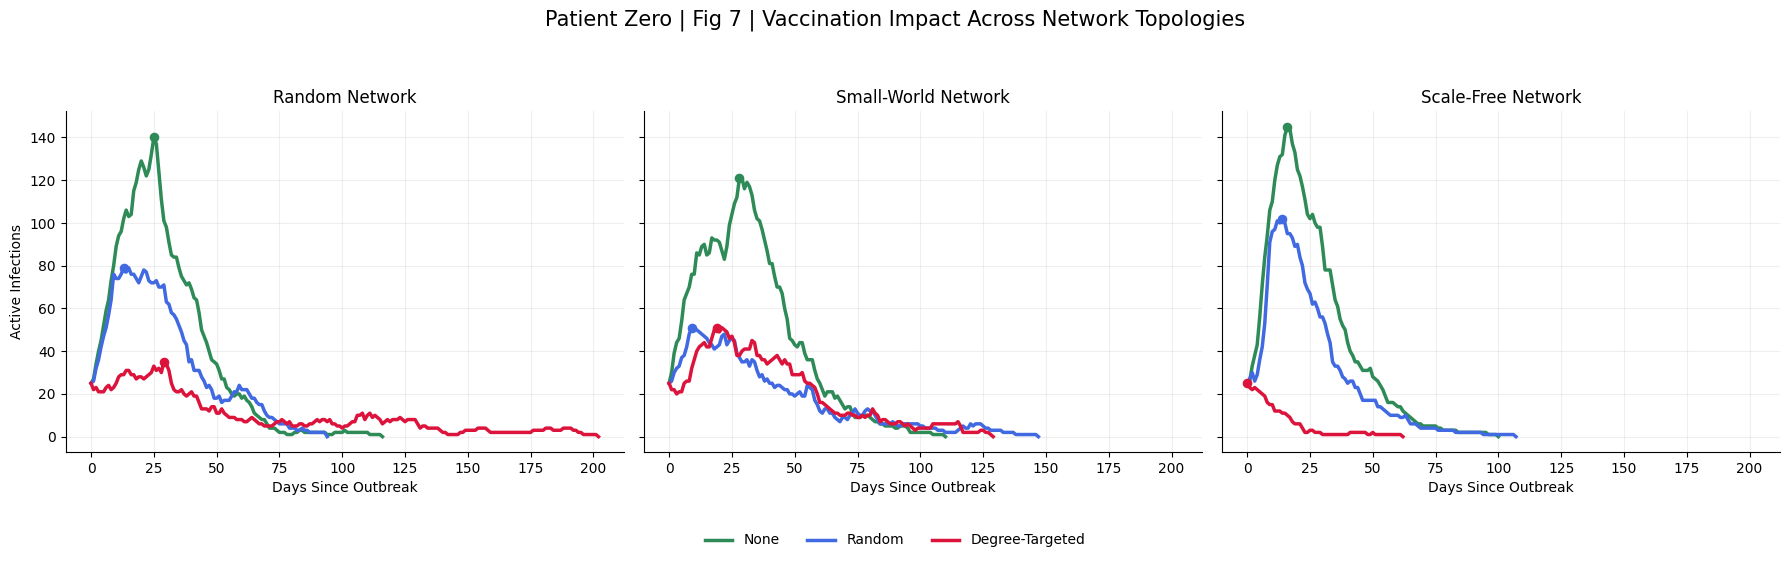

In [64]:
#visualization
strategy_colors={"None":"seagreen","Random":"royalblue","Degree-Targeted":"crimson"}

fig,axes = plt.subplots(1,3,figsize=(18, 5.5),sharex=True,sharey=True)

for ax,(topology, strategy_results) in zip(axes, topology_sirv_results.items()):
    for strategy, result in strategy_results.items():
        ax.plot(result["day"],result["infected"],color=strategy_colors[strategy],linewidth=2.5,label=strategy)

        peak_idx=result["infected"].idxmax()
        ax.scatter(result.loc[peak_idx, "day"],result.loc[peak_idx, "infected"],color=strategy_colors[strategy],s=35,zorder=5)

    ax.set_title(f"{topology.title()} Network",fontsize=12)
    ax.set_xlabel("Days Since Outbreak")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Active Infections")

handles,labels=axes[0].get_legend_handles_labels()

fig.legend(handles,labels,loc="lower center",bbox_to_anchor=(0.5, -0.02),ncol=3,frameon=False)

fig.suptitle("Patient Zero | Fig 7 | Vaccination Impact Across Network Topologies",fontsize=15)

plt.tight_layout(rect=[0,0.07,1,0.93])
plt.show()


<a name="notebook-monte-carlo-experiments"></a>

##### *Monte Carlo Experiments*

**Experimental Design**

| Experimental factor | Values |
|---|---|
| Population | 500 |
| Network topologies | Random, Small-world, Scale-free |
| Initial infected proportion | 1%, 5%, 10% |
| Transmission rate | 0.2, 0.3, 0.4 |
| Recovery rate | 0.10, 0.20, 0.25 |
| Vaccination configurations | 7 |
| Repetitions per scenario | 100 |
| Maximum simulation duration | 1,000 days |

The factorial design contains $3\times3\times3\times3\times7=567$ scenarios and $567\times100=56{,}700$ simulations. The 81 matched groups each represent one topology and one combination of initial infection, transmission and recovery parameters. Each group contains all seven vaccination configurations. The three network realizations remain fixed, and the Monte Carlo master seed is 2037.

In [65]:
#parameters
mc_initial_infected_pcts=[0.01,0.05,0.1]
mc_beta_values=[0.2,0.3,0.4]
mc_gamma_values=[0.1,0.2,0.25]
mc_repetitions=100

mc_scenarios=[]

for topology,initial_pct,beta,gamma,config in product(
    networks.keys(),
    mc_initial_infected_pcts,
    mc_beta_values,
    mc_gamma_values,
    vacc_configs
):
    mc_scenarios.append({
        "scenario_id":len(mc_scenarios),
        "topology":topology,
        "initial_infected_pct":initial_pct,
        "beta":beta,
        "gamma":gamma,
        "vaccination_strategy":config["strategy"],
        "vaccination_coverage":config["coverage"]
    })

mc_scenarios_df=pd.DataFrame(mc_scenarios)

print(f"Unique Scenarios: {len(mc_scenarios_df)}")
print(f"Planned Simulations: {len(mc_scenarios_df)*mc_repetitions}")

mc_scenarios_df.head(10)

Unique Scenarios: 567
Planned Simulations: 56700


,scenario_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage
0,0,Random,0.01,0.2,0.1,None,0.0
1,1,Random,0.01,0.2,0.1,Random,0.1
2,2,Random,0.01,0.2,0.1,Random,0.2
3,3,Random,0.01,0.2,0.1,Random,0.3
4,4,Random,0.01,0.2,0.1,Degree-Targeted,0.1
5,5,Random,0.01,0.2,0.1,Degree-Targeted,0.2
6,6,Random,0.01,0.2,0.1,Degree-Targeted,0.3
7,7,Random,0.01,0.2,0.2,None,0.0
8,8,Random,0.01,0.2,0.2,Random,0.1
9,9,Random,0.01,0.2,0.2,Random,0.2


In [66]:
mc_master_seed=2037

def create_mc_rngs(comparison_id,repetition_id):
    seed_sequence=np.random.SeedSequence([mc_master_seed,comparison_id,repetition_id])
    vacc_seed,init_seed,disease_seed=seed_sequence.spawn(3)
    return {
        "vaccination":np.random.default_rng(vacc_seed),
        "initialization":np.random.default_rng(init_seed),
        "disease":np.random.default_rng(disease_seed)
    }

In [67]:

#rules
mc_design={
    "population":network_population,
    "network_realizations":"fixed",
    "network_seed":network_seed,
    "repetitions":mc_repetitions,
    "master_seed":mc_master_seed,
    "vaccination_timing":"pre-outbreak",
    "vaccination_efficacy":1.0,
    "initial_infected_basis":"total_population",
    "initial_infected_eligibility":"unvaccinated",
    "primary_metric":"final_outbreak_size",
    "secondary_metrics": ["peak_infected","duration","attack_rate"],
    "max_days":1000
}

mc_design


{'population': 500,
 'network_realizations': 'fixed',
 'network_seed': 42,
 'repetitions': 100,
 'master_seed': 2037,
 'vaccination_timing': 'pre-outbreak',
 'vaccination_efficacy': 1.0,
 'initial_infected_basis': 'total_population',
 'initial_infected_eligibility': 'unvaccinated',
 'primary_metric': 'final_outbreak_size',
 'secondary_metrics': ['peak_infected', 'duration', 'attack_rate'],
 'max_days': 1000}

In [68]:

#validation
scenario_columns = ["topology","initial_infected_pct","beta","gamma","vaccination_strategy","vaccination_coverage"]

assert len(mc_scenarios_df)==567
assert mc_scenarios_df[scenario_columns].duplicated().sum()==0
assert mc_scenarios_df["scenario_id"].is_unique

#189 row per topology
assert (mc_scenarios_df.groupby("topology").size()==189).all()

#81 rows per vaccination config
assert (mc_scenarios_df.groupby(["vaccination_strategy", "vaccination_coverage"]).size()==81).all()

#reproducibility
rngs_a=create_mc_rngs(1,12)
rngs_b=create_mc_rngs(1,12)
rngs_c=create_mc_rngs(1,13)

draws_a=rngs_a["disease"].random(10)
draws_b=rngs_b["disease"].random(10)
draws_c=rngs_c["disease"].random(10)

assert np.array_equal(draws_a,draws_b)
assert not np.array_equal(draws_a,draws_c)

print("Scenario matrix validation: PASSED")
print("Random seed reproducibility: PASSED")
print("Total planned simulations:",567*mc_repetitions)

Scenario matrix validation: PASSED
Random seed reproducibility: PASSED
Total planned simulations: 56700


**Monte Carlo Engine**

A seed sequence derived from the master seed, comparison identifier and repetition identifier spawns three streams for vaccination, initial infection assignment and disease progression. All seven configurations in a matched repetition start with the same three stream seeds. Random vaccination uses the vaccination stream, while the baseline and degree-targeted allocation are deterministic. Vaccination changes the eligible initial-infection pool and can change disease states and subsequent random-number consumption, so paired runs can realize different individual events.

Final outbreak size is the primary outcome. Peak infections, duration and attack rate are designated secondary outcomes, and peak day is also recorded. A pilot of 35 simulations (seven configurations and five repetitions) checked coverage, metric bounds, completion and uniqueness. Repeating a pilot scenario with the same identifiers reproduced its output.

In [69]:
#updated the run_stochastic_sirv function to take into account different rngs (vacc_rng, init_rng, and disease_rng)
#updated the create_mc_rngs function to have comparison_id as an additional parameter

comparison_cols=["topology","initial_infected_pct","beta","gamma"]

comparison_groups=mc_scenarios_df[comparison_cols].drop_duplicates().reset_index(drop=True)
comparison_groups["comparison_id"]=np.arange(1,len(comparison_groups)+1)

mc_scenarios_df=mc_scenarios_df.merge(comparison_groups,on=comparison_cols,how="left",validate="many_to_one")

assert len(comparison_groups)==81
assert mc_scenarios_df["comparison_id"].notna().all()

print("Comparison groups:",len(comparison_groups))

Comparison groups: 81


In [70]:

def summarize_mc_simulation(scenario,repetition_id,simulation):
    peak_idx=simulation["infected"].idxmax()
    final_infections=(simulation["recovered"].iloc[-1]+simulation["infected"].iloc[-1])
    population=mc_design["population"]

    return {
        "scenario_id":int(scenario["scenario_id"]),
        "comparison_id":int(scenario["comparison_id"]),
        "repetition_id":repetition_id,
        "topology":scenario["topology"],
        "initial_infected_pct":scenario["initial_infected_pct"],
        "beta":scenario["beta"],
        "gamma":scenario["gamma"],
        "vaccination_strategy":scenario["vaccination_strategy"],
        "vaccination_coverage":scenario["vaccination_coverage"],
        "peak_infected":int(simulation.loc[peak_idx,"infected"]),
        "peak_day":int(simulation.loc[peak_idx,"day"]),
        "final_outbreak_size":int(final_infections),
        "duration":int(simulation["day"].iloc[-1]),
        "attack_rate":final_infections/population,
        "vaccinated_count":int(simulation["vaccinated"].iloc[0]),
        "completed":bool(simulation["infected"].iloc[-1]==0)
    }


In [71]:
def run_mc_scenario(scenario,repetitions=100):
    results=[]
    
    for repetition_id in range(repetitions):
        rngs=create_mc_rngs(
            comparison_id=int(scenario["comparison_id"]),
            repetition_id=repetition_id
        )
        
        simulation=run_stochastic_sirv(
            graph=networks[scenario["topology"]],
            initial_infected_pct=scenario["initial_infected_pct"],
            beta=scenario["beta"],
            gamma=scenario["gamma"],
            vacc_strategy=scenario["vaccination_strategy"],
            vacc_coverage=scenario["vaccination_coverage"],
            max_days=mc_design["max_days"],
            rngs=rngs
        )
        
        results.append(summarize_mc_simulation(scenario,repetition_id,simulation))
    return pd.DataFrame(results)

In [72]:

#testing with 5 repetitions
pilot_scenarios = mc_scenarios_df[
    (mc_scenarios_df["topology"]=="Scale-free")
    & (mc_scenarios_df["initial_infected_pct"]==0.05)
    & (mc_scenarios_df["beta"]==0.3)
    & (mc_scenarios_df["gamma"]==0.1)
]

pilot_results = pd.concat(
    [
        run_mc_scenario(scenario,repetitions=5)
        for _,scenario in pilot_scenarios.iterrows()
    ],
    ignore_index=True
)

print("Pilot simulations:",len(pilot_results))
pilot_results.head(10)


Pilot simulations: 35


,scenario_id,comparison_id,repetition_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage,peak_infected,peak_day,final_outbreak_size,duration,attack_rate,vaccinated_count,completed
0,462,67,0,Scale-free,0.05,0.3,0.1,None,0.0,145,14,382,108,0.764,0,True
1,462,67,1,Scale-free,0.05,0.3,0.1,None,0.0,158,15,415,79,0.830,0,True
2,462,67,2,Scale-free,0.05,0.3,0.1,None,0.0,164,11,421,99,0.842,0,True
3,462,67,3,Scale-free,0.05,0.3,0.1,None,0.0,152,12,414,106,0.828,0,True
4,462,67,4,Scale-free,0.05,0.3,0.1,None,0.0,123,21,395,85,0.790,0,True
5,463,67,0,Scale-free,0.05,0.3,0.1,Random,0.1,132,11,314,94,0.628,50,True
6,463,67,1,Scale-free,0.05,0.3,0.1,Random,0.1,125,13,314,64,0.628,50,True
7,463,67,2,Scale-free,0.05,0.3,0.1,Random,0.1,131,15,352,91,0.704,50,True
8,463,67,3,Scale-free,0.05,0.3,0.1,Random,0.1,130,18,366,87,0.732,50,True
9,463,67,4,Scale-free,0.05,0.3,0.1,Random,0.1,110,14,303,78,0.606,50,True


In [73]:
#validate the test case
assert len(pilot_results)==35
assert not pilot_results[["scenario_id", "repetition_id"]].duplicated().any()
assert pilot_results["repetition_id"].between(0,4).all()
assert pilot_results["vaccinated_count"].tolist() == (pilot_results["vaccination_coverage"]*network_population).round().astype(int).tolist()
assert pilot_results["final_outbreak_size"].between(25,network_population).all()
assert pilot_results["peak_infected"].between(1, network_population).all()
assert pilot_results["attack_rate"].between(0,1).all()
assert pilot_results["duration"].between(0,mc_design["max_days"]).all()
assert pilot_results["completed"].all()

print("Pilot validation: PASSED")


Pilot validation: PASSED


In [74]:
test_scenario=pilot_scenarios.iloc[0]

test_a=run_mc_scenario(test_scenario,repetitions=5)
test_b=run_mc_scenario(test_scenario,repetitions=5)

pd.testing.assert_frame_equal(test_a,test_b)

print("Monte Carlo reproducibility: PASSED")

Monte Carlo reproducibility: PASSED


**Full Monte Carlo Experiment**

The 567 scenarios are divided into 27 batches of 21 scenarios, with 100 repetitions per scenario and 2,100 simulations per batch. Batch CSV checkpoints allow completed work to be reused after an interruption. The saved timing benchmark was interrupted. A subsequent check validated the existing first-batch checkpoint, and the full run reused it. The final consolidation verified scenario–repetition coverage and uniqueness and recorded 56,700 completed outbreaks in `patient_zero_monte_carlo_results.csv`.

In [75]:
#mc configuration
mc_batch_size=21
mc_output_dir=Path("outputs/monte_carlo")
mc_output_dir.mkdir(parents=True,exist_ok=True)

mc_total_scenarios=len(mc_scenarios_df)
mc_total_batches=math.ceil(mc_total_scenarios/mc_batch_size)

print("Total scenarios:",mc_total_scenarios)
print("Repetitions per scenario:",mc_repetitions)
print("Total simulations:",mc_total_scenarios*mc_repetitions)
print("Scenarios per batch:",mc_batch_size)
print("Total batches:",mc_total_batches)
print("Output directory:",mc_output_dir)

Total scenarios: 567
Repetitions per scenario: 100
Total simulations: 56700
Scenarios per batch: 21
Total batches: 27
Output directory: outputs\monte_carlo


In [76]:
mc_execution_df=(mc_scenarios_df.sort_values("scenario_id").reset_index(drop=True).copy())
mc_execution_df["batch_id"]=(np.arange(len(mc_execution_df))//mc_batch_size)+1

assert len(mc_execution_df)==567
assert mc_execution_df["scenario_id"].is_unique
assert mc_execution_df["batch_id"].nunique()==27
assert (mc_execution_df.groupby("batch_id").size()==21).all()

print("Batch assignments: PASSED")
mc_execution_df.groupby("batch_id").size().head(10)

Batch assignments: PASSED


batch_id
1     21
2     21
3     21
4     21
5     21
6     21
7     21
8     21
9     21
10    21
dtype: int64

In [92]:
def run_mc_batch(batch_id,repetitions=mc_repetitions,overwrite=False):
    batch_scenarios=mc_execution_df[mc_execution_df["batch_id"]==batch_id]
    
    if batch_scenarios.empty:
        raise ValueError(f"Batch {batch_id} does not exist")
    
    output_path=mc_output_dir/f"mc_batch_{batch_id:02d}.csv"
    expected_rows=len(batch_scenarios)*repetitions
    
    if output_path.exists() and not overwrite:
        existing=pd.read_csv(output_path)
        expected_pairs={(int(sid),rep) for sid in batch_scenarios["scenario_id"] for rep in range(repetitions)}
        actual_pairs=set(zip(existing["scenario_id"],existing["repetition_id"])) if {"scenario_id","repetition_id"}.issubset(existing.columns) else set()
        
        if (
            len(existing)==expected_rows
            and len(actual_pairs)==expected_rows
            and actual_pairs==expected_pairs
        ):
            print(f"Batch {batch_id:02d}: valid checkpoint found, skipping")
            return existing
        
        raise ValueError(
            f"Batch {batch_id:02d} has an invalid checkpoint"
            "inspect it before rerunning with overwrite=True"
        )
    print(f"Starting batch {batch_id:02d}/{mc_total_batches}...")
    start_time=timer.perf_counter()
    
    results=[
        run_mc_scenario(scenario,repetitions=repetitions)
        for _,scenario in batch_scenarios.iterrows()
    ]

    batch_results=pd.concat(results,ignore_index=True)

    assert len(batch_results)==expected_rows
    assert not batch_results.duplicated(["scenario_id","repetition_id"]).any()

    temp_path=output_path.with_suffix(".tmp")
    batch_results.to_csv(temp_path,index=False)
    os.replace(temp_path,output_path)

    elapsed=timer.perf_counter()-start_time

    print(
        f"Batch {batch_id:02d} complete: "
        f"{len(batch_results):,} simulations "
        f"in {elapsed/60:.1f} minutes"
    )

    return batch_results

In [82]:
#benchmark
benchmark_start=timer.perf_counter()
benchmark_results=run_mc_batch(batch_id=1,repetitions=mc_repetitions,overwrite=True)
benchmark_elapsed=timer.perf_counter()-benchmark_start

estimated_total_minutes=benchmark_elapsed*mc_total_batches/60

print(f"\nBenchmark duration: {benchmark_elapsed/60:.2f} minutes")
print(f"Estimated full experiment: {estimated_total_minutes/60:.2f} hours")
print(f"Completed simulations: {len(benchmark_results):,}")

Starting batch 01/27...


KeyboardInterrupt: 

In [ ]:
benchmark_path=mc_output_dir/"mc_batch_01.csv"

saved_benchmark=pd.read_csv(benchmark_path)

assert len(saved_benchmark)==2100
assert saved_benchmark["scenario_id"].nunique()==21
assert saved_benchmark["repetition_id"].nunique()==100
assert not saved_benchmark.duplicated(["scenario_id", "repetition_id"]).any()

assert saved_benchmark["completed"].all()

print("Full batch validation: PASSED")
print("Saved checkpoint:",benchmark_path)

Full batch validation: PASSED
Saved checkpoint: outputs\monte_carlo\mc_batch_01.csv


In [ ]:
# full execution
experiment_start=timer.perf_counter()

for batch_id in range(1,mc_total_batches+1):
    run_mc_batch(batch_id=batch_id,repetitions=mc_repetitions,overwrite=False)

    completed=batch_id*mc_batch_size*mc_repetitions
    progress=100*completed/(mc_total_scenarios*mc_repetitions)

    print(f"Progress: {progress:.1f}% ({completed:,} simulations)\n")

experiment_elapsed=timer.perf_counter()-experiment_start

print("="*50)
print("MONTE CARLO EXECUTION FINISHED")
print(f"Elapsed time: {experiment_elapsed/3600:.2f} hours")
print(f"Expected simulations: {mc_total_scenarios*mc_repetitions:,}")
print("="*50)

Batch 01: valid checkpoint found, skipping
Progress: 3.7% (2,100 simulations)

Starting batch 02/27...
Batch 02 complete: 2,100 simulations in 5.3 minutes
Progress: 7.4% (4,200 simulations)

Starting batch 03/27...
Batch 03 complete: 2,100 simulations in 5.0 minutes
Progress: 11.1% (6,300 simulations)

Starting batch 04/27...
Batch 04 complete: 2,100 simulations in 5.0 minutes
Progress: 14.8% (8,400 simulations)

Starting batch 05/27...
Batch 05 complete: 2,100 simulations in 4.7 minutes
Progress: 18.5% (10,500 simulations)

Starting batch 06/27...
Batch 06 complete: 2,100 simulations in 3.9 minutes
Progress: 22.2% (12,600 simulations)

Starting batch 07/27...
Batch 07 complete: 2,100 simulations in 6.2 minutes
Progress: 25.9% (14,700 simulations)

Starting batch 08/27...
Batch 08 complete: 2,100 simulations in 5.8 minutes
Progress: 29.6% (16,800 simulations)

Starting batch 09/27...
Batch 09 complete: 2,100 simulations in 3.9 minutes
Progress: 33.3% (18,900 simulations)

Starting batc

In [ ]:
#load all completed batch checkpoints
batch_files=sorted(mc_output_dir.glob("mc_batch_*.csv"))

assert len(batch_files)==mc_total_batches

mc_results_df=pd.concat([pd.read_csv(path) for path in batch_files],ignore_index=True)

#validation
assert len(mc_results_df)==56700
assert mc_results_df["scenario_id"].nunique()==567
assert mc_results_df["repetition_id"].nunique()==100

assert not mc_results_df.duplicated(["scenario_id","repetition_id"]).any()

expected_pairs = pd.MultiIndex.from_product(
    [mc_scenarios_df["scenario_id"].unique(),range(mc_repetitions)],
    names=["scenario_id","repetition_id"]
)

actual_pairs=pd.MultiIndex.from_frame(mc_results_df[["scenario_id","repetition_id"]])

assert len(actual_pairs.difference(expected_pairs))==0
assert len(expected_pairs.difference(actual_pairs))==0

print("Full experiment validation: PASSED")
print("Total simulations:",len(mc_results_df))
print("Completed outbreaks:",mc_results_df["completed"].sum())

Full experiment validation: PASSED
Total simulations: 56700
Completed outbreaks: 56700


In [ ]:
#consolidated Monte Carlo results
mc_final_path=mc_output_dir/"patient_zero_monte_carlo_results.csv"

mc_results_df.to_csv(mc_final_path,index=False)

print("Consolidated dataset saved:",mc_final_path)
print("Dataset dimensions:",mc_results_df.shape)

Consolidated dataset saved: outputs\monte_carlo\patient_zero_monte_carlo_results.csv
Dataset dimensions: (56700, 16)


**Loading Saved Monte Carlo Results**

The consolidated CSV can supply the downstream analyses directly, bypassing the original simulation and batch computation.

In [109]:
mc_final_path = mc_output_dir / "patient_zero_monte_carlo_results.csv"

mc_results_df = pd.read_csv(mc_final_path)

print("Loaded Monte Carlo results:", mc_results_df.shape)

Loaded Monte Carlo results: (56700, 16)


<a name="notebook-statistical-analysis"></a>

##### *Statistical Analysis*

**Descriptive Statistics**

CSV ingestion can parse the unvaccinated strategy label **None** as missing. The analysis confirms that all 8,100 affected rows have zero coverage and zero vaccinated individuals before restoring the label. Additional checks validate outcome ranges, consistency and completion.

| Outcome | Implementation |
|---|---|
| Final outbreak size | Recovered plus still-infected individuals at the last recorded day, including initial infections |
| Peak infections | Maximum simultaneous infected count |
| Peak day | First recorded day at that maximum |
| Duration | Last recorded day, corresponding to extinction for completed outbreaks |
| Attack rate | Final outbreak size divided by total population, stored as a proportion |

Descriptive statistics summarize 56,700 outcomes, and the scenario table aggregates 100 repetitions for each of 567 scenarios. Fig 8, *Monte Carlo Epidemic Outcome Distributions*, shows wide variation in outbreak size and duration and many peaks occurring early. The distributions combine different epidemiological settings and interventions.

In [110]:
mc_analysis_df=mc_results_df.copy()

mc_analysis_df.info()

missing_values=mc_analysis_df.isna().sum()
display(missing_values[missing_values>0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56700 entries, 0 to 56699
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   scenario_id           56700 non-null  int64  
 1   comparison_id         56700 non-null  int64  
 2   repetition_id         56700 non-null  int64  
 3   topology              56700 non-null  object 
 4   initial_infected_pct  56700 non-null  float64
 5   beta                  56700 non-null  float64
 6   gamma                 56700 non-null  float64
 7   vaccination_strategy  48600 non-null  object 
 8   vaccination_coverage  56700 non-null  float64
 9   peak_infected         56700 non-null  int64  
 10  peak_day              56700 non-null  int64  
 11  final_outbreak_size   56700 non-null  int64  
 12  duration              56700 non-null  int64  
 13  attack_rate           56700 non-null  float64
 14  vaccinated_count      56700 non-null  int64  
 15  completed          

vaccination_strategy    8100
dtype: int64

In [111]:
missing_strategy=mc_analysis_df["vaccination_strategy"].isna()
assert missing_strategy.sum()==8100
assert(mc_analysis_df.loc[missing_strategy,"vaccination_coverage"]==0).all()
assert(mc_analysis_df.loc[missing_strategy,"vaccinated_count"]==0).all()

mc_analysis_df["vaccination_strategy"]=mc_analysis_df["vaccination_strategy"].fillna("None")

print("Vaccination strategy validation: PASSED")
print("Remaining missing values:",mc_analysis_df.isna().sum().sum())

Vaccination strategy validation: PASSED
Remaining missing values: 0


In [112]:
#epidemiological outcome constraints
N=500

assert mc_analysis_df["peak_infected"].between(0,N).all()
assert mc_analysis_df["final_outbreak_size"].between(0,N).all()
assert mc_analysis_df["vaccinated_count"].between(0,N).all()

assert (mc_analysis_df["final_outbreak_size"]+mc_analysis_df["vaccinated_count"]<=N).all()

assert (mc_analysis_df["peak_infected"]<=mc_analysis_df["final_outbreak_size"]).all()
assert (mc_analysis_df["duration"]>=0).all()
assert (mc_analysis_df["peak_day"]<=mc_analysis_df["duration"]).all()
assert mc_analysis_df["attack_rate"].between(0,1).all()
assert mc_analysis_df["completed"].all()

print("Epidemiological integrity validation: PASSED")

Epidemiological integrity validation: PASSED


In [113]:
outcome_cols=["final_outbreak_size","peak_infected","peak_day","duration","attack_rate"]
summary_stats=mc_analysis_df[outcome_cols].describe(percentiles=[0.05,0.25,0.5,0.75,0.95]).T.round(3)
display(summary_stats)

,count,mean,std,min,5%,25%,50%,75%,95%,max
final_outbreak_size,56700.0,152.018,120.032,5.00,8.000,50.0,125.00,236.000,383.000,490.00
peak_infected,56700.0,48.558,38.344,5.00,5.000,25.0,48.00,62.000,128.000,235.00
peak_day,56700.0,9.452,13.846,0.00,0.000,0.0,5.00,13.000,35.000,232.00
duration,56700.0,56.834,37.703,1.00,12.000,29.0,46.00,80.000,127.000,375.00
attack_rate,56700.0,0.304,0.240,0.01,0.016,0.1,0.25,0.472,0.766,0.98


In [114]:
scenario_summary=mc_analysis_df.groupby(
    ["scenario_id","comparison_id","topology","initial_infected_pct",
    "beta","gamma","vaccination_strategy","vaccination_coverage"],as_index=False).agg(
        mean_outbreak=("final_outbreak_size","mean"),
        sd_outbreak=("final_outbreak_size","std"),
        median_outbreak=("final_outbreak_size","median"),
        mean_peak=("peak_infected","mean"),
        mean_peak_day=("peak_day","mean"),
        mean_duration=("duration","mean"),
        mean_attack_rate=("attack_rate","mean"),
        repetitions=("repetition_id","count"))

assert len(scenario_summary)==567
assert (scenario_summary["repetitions"]==100).all()

display(scenario_summary.head())

,scenario_id,comparison_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage,mean_outbreak,sd_outbreak,median_outbreak,mean_peak,mean_peak_day,mean_duration,mean_attack_rate,repetitions
0,0,1,Random,0.01,0.2,0.1,None,0.0,319.00,83.671194,341.5,62.71,50.25,145.64,0.63800,100
1,1,1,Random,0.01,0.2,0.1,Random,0.1,234.12,85.388983,261.0,42.51,53.18,142.84,0.46824,100
2,2,1,Random,0.01,0.2,0.1,Random,0.2,154.30,72.879796,177.5,26.92,51.69,138.80,0.30860,100
3,3,1,Random,0.01,0.2,0.1,Random,0.3,68.28,48.679965,65.5,14.86,33.38,94.98,0.13656,100
4,4,1,Random,0.01,0.2,0.1,Degree-Targeted,0.1,111.14,84.191343,112.5,19.41,44.73,123.49,0.22228,100


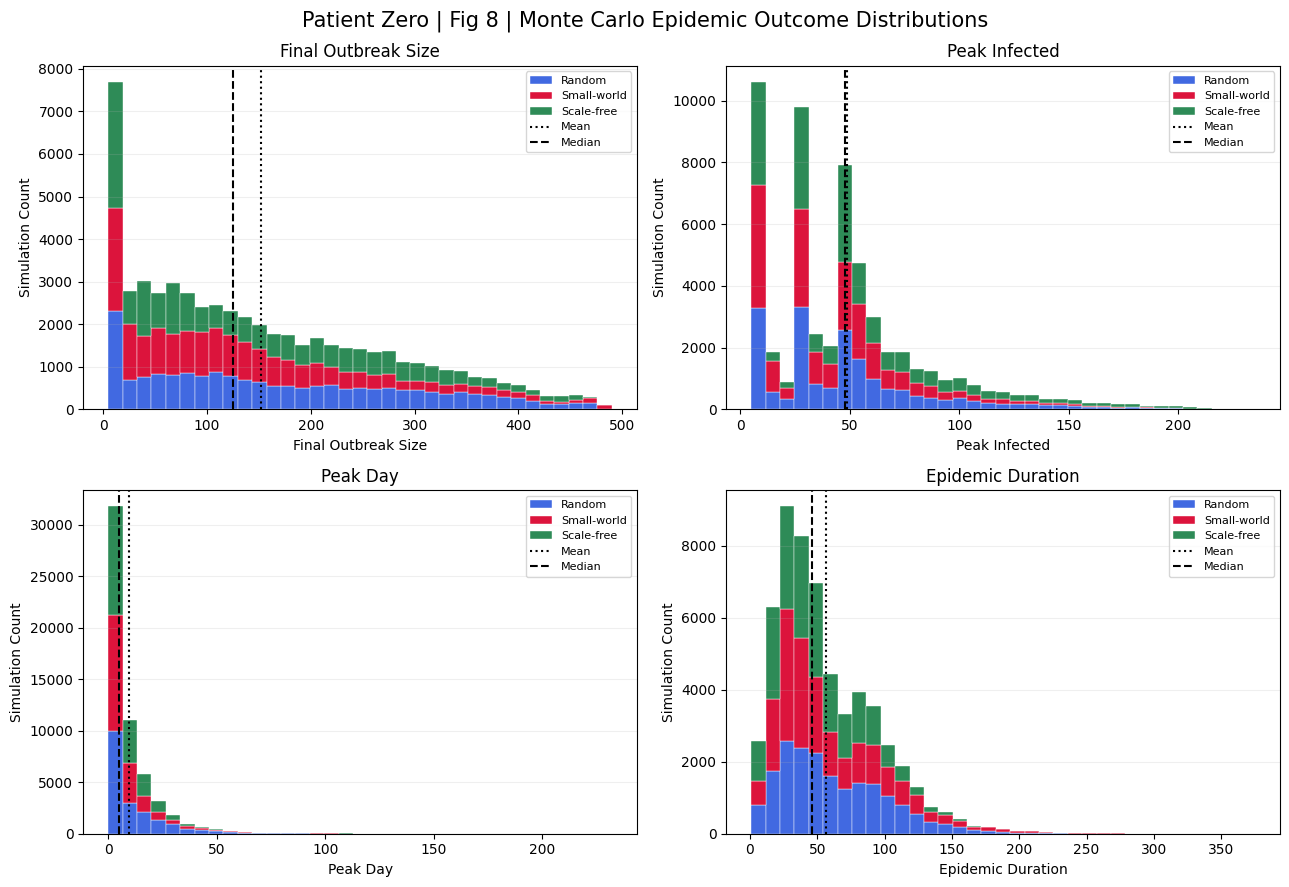

In [115]:
#visualization
fig,axes=plt.subplots(2,2,figsize=(13,9))

plot_metrics = {
    "final_outbreak_size":"Final Outbreak Size",
    "peak_infected":"Peak Infected",
    "peak_day":"Peak Day",
    "duration":"Epidemic Duration"
}

for ax,(col,title) in zip(axes.flat, plot_metrics.items()):
    values=mc_analysis_df[col]

    topology_values=[mc_analysis_df.loc[mc_analysis_df["topology"]==topology,col]for topology in topology_order]

    ax.hist(topology_values,bins=35,stacked=True,color=[topology_colors[t] for t in topology_order],label=topology_order,edgecolor="white",linewidth=0.3)

    ax.axvline(values.mean(),color="black",linestyle=":",linewidth=1.5,label="Mean")
    ax.axvline(values.median(),color="black",linestyle="--",linewidth=1.5,label="Median")

    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel("Simulation Count")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.2)

fig.suptitle("Patient Zero | Fig 8 | Monte Carlo Epidemic Outcome Distributions",fontsize=15)

plt.tight_layout()
plt.show()

In [ ]:
'''
#visualization - epidemic outcomes across network topologies
fig,axes=plt.subplots(1,2,figsize=(14,5))

sns.violinplot(data=mc_analysis_df,x="topology",y="final_outbreak_size",order=topology_order,inner="quartile",cut=0,ax=axes[0],hue="topology",palette=topology_colors,legend=False)
sns.violinplot(data=mc_analysis_df,x="topology",y="duration",order=topology_order,inner="quartile",cut=0,ax=axes[1],hue="topology",palette=topology_colors,legend=False)

axes[0].set_title("Outbreak Size by Network Topology")
axes[0].set_ylabel("Final Outbreak Size")

axes[1].set_title("Epidemic Duration by Network Topology")
axes[1].set_ylabel("Duration (Days)")

for ax in axes:
    ax.set_xlabel("Network Topology")
    ax.grid(axis="y",alpha=0.2)

fig.suptitle("Patient Zero | Fig 9 | Epidemic Outcome Variability Across Network Structures",fontsize=15)
plt.tight_layout()
plt.show()
'''

'\n#visualization - epidemic outcomes across network topologies\nfig,axes=plt.subplots(1,2,figsize=(14,5))\n\nsns.violinplot(data=mc_analysis_df,x="topology",y="final_outbreak_size",order=topology_order,inner="quartile",cut=0,ax=axes[0],hue="topology",palette=topology_colors,legend=False)\nsns.violinplot(data=mc_analysis_df,x="topology",y="duration",order=topology_order,inner="quartile",cut=0,ax=axes[1],hue="topology",palette=topology_colors,legend=False)\n\naxes[0].set_title("Outbreak Size by Network Topology")\naxes[0].set_ylabel("Final Outbreak Size")\n\naxes[1].set_title("Epidemic Duration by Network Topology")\naxes[1].set_ylabel("Duration (Days)")\n\nfor ax in axes:\n    ax.set_xlabel("Network Topology")\n    ax.grid(axis="y",alpha=0.2)\n\nfig.suptitle("Patient Zero | Fig 9 | Epidemic Outcome Variability Across Network Structures",fontsize=15)\nplt.tight_layout()\nplt.show()\n'

In [116]:
#validation
assert summary_stats.shape[0]==5
assert scenario_summary["scenario_id"].nunique()==567
assert scenario_summary["repetitions"].sum()==56700
assert not scenario_summary.isna().any().any()

print("Descriptive statistics validation: PASSED")

Descriptive statistics validation: PASSED


**Network Topology Analysis**

The baseline isolates 8,100 unvaccinated simulations across 81 scenarios. The scale-free realization has the largest mean outbreak, highest mean peak, highest mean attack rate and shortest mean duration. The small-world realization has the smallest mean outbreak and lowest mean peak and attack rate. Fig 9, *Epidemic Outcomes by Network Topology with No Vaccination*, shows the variability underlying these averages.

Fig 10, *Transmission–Recovery Sensitivity*, compares mean outbreak size across rate pairs within each topology, averaging over the three initial infected proportions. The saved heatmaps show larger mean outbreaks at higher transmission and lower recovery rates. In Fig 11, *Initial Infection Sensitivity by Network Topology*, mean outbreak size increases with the initial infected proportion in all three realizations, with the largest increase in the small-world realization.

In [117]:
#unvaccinated baseline simulations
baseline_df = mc_analysis_df.loc[mc_analysis_df["vaccination_strategy"]=="None"].copy()

assert len(baseline_df)==8100
assert baseline_df["scenario_id"].nunique()==81
assert baseline_df["comparison_id"].nunique()==81
assert (baseline_df["vaccination_coverage"]==0).all()
assert (baseline_df["vaccinated_count"]==0).all()

print("Baseline dataset validation: PASSED")
print("Baseline simulations:",len(baseline_df))

display(baseline_df.groupby("topology").size())

Baseline dataset validation: PASSED
Baseline simulations: 8100


topology
Random         2700
Scale-free     2700
Small-world    2700
dtype: int64

In [118]:
baseline_summary=(baseline_df.groupby("topology")[outcome_cols].agg(["mean","std","median"]).round(2))
display(baseline_summary)

final_outbreak_size                peak_infected                \
                           mean     std median          mean    std median   
topology                                                                     
Random                   280.94  139.16  311.0         78.05  54.30   65.0   
Scale-free               291.84  110.38  308.0         95.92  53.68   88.0   
Small-world              216.95  149.31  195.0         57.63  43.41   50.0   

            peak_day               duration               attack_rate        \
                mean    std median     mean    std median        mean   std   
topology                                                                      
Random         15.55  14.43   13.0    71.40  34.11   68.0        0.56  0.28   
Scale-free     12.95   8.35   12.0    62.29  25.70   56.0        0.58  0.22   
Small-world    13.82  17.87    8.0    70.27  45.11   56.0        0.43  0.30   

                    
            median  
topology            
Random        0.62  
Scale-free    0.62  
Small-world   0.39

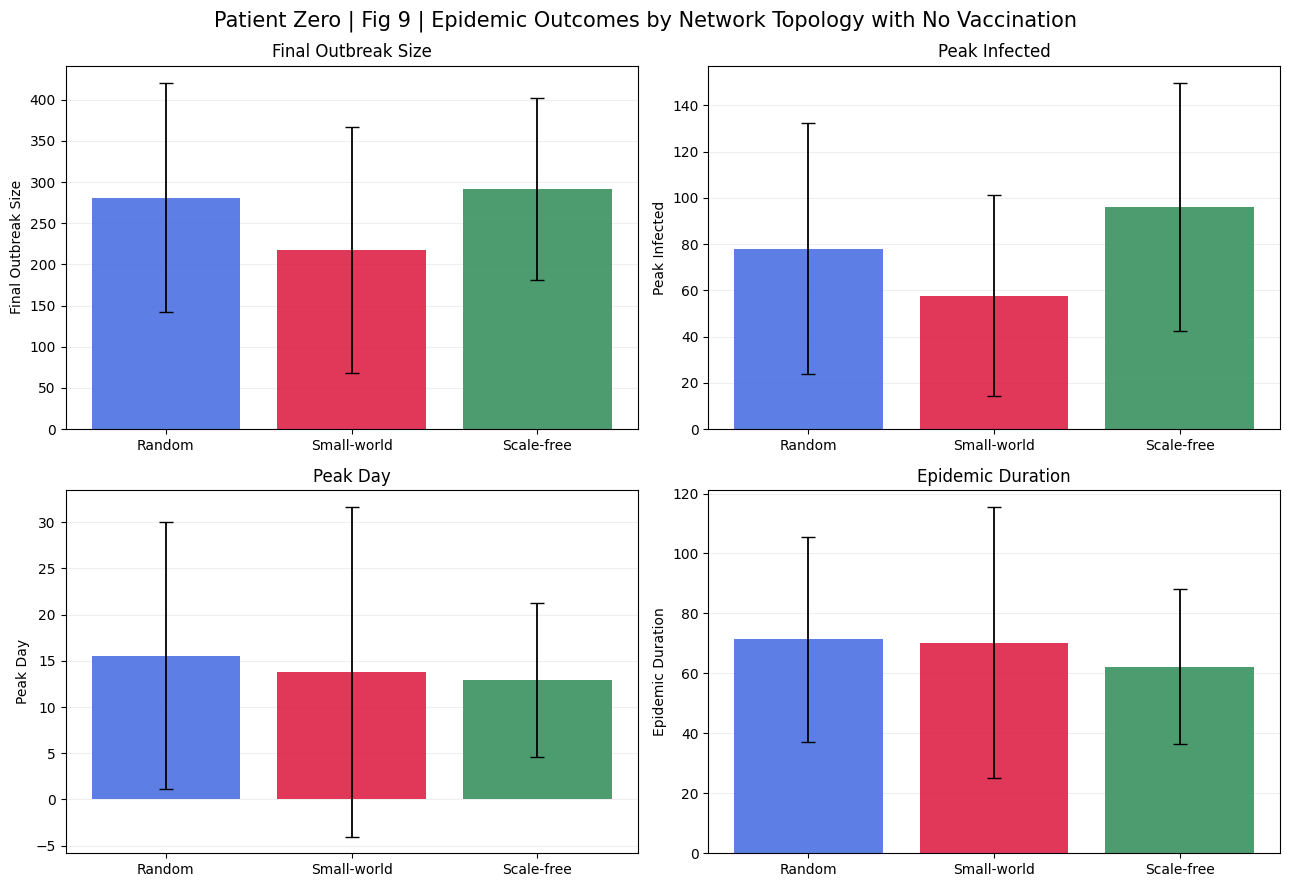

In [119]:
#visualization - baseline (no vacc) - epidemic outcomes across network topologies
fig,axes = plt.subplots(2,2,figsize=(13,9))

metrics = {
    "final_outbreak_size":"Final Outbreak Size",
    "peak_infected":"Peak Infected",
    "peak_day":"Peak Day",
    "duration":"Epidemic Duration"
}

for ax,(metric,title) in zip(axes.flat,metrics.items()):
    stats = (baseline_df.groupby("topology")[metric].agg(["mean", "std"]).reindex(topology_order))

    ax.bar(topology_order,stats["mean"],yerr=stats["std"],capsize=5,color=[topology_colors[t] for t in topology_order],alpha=0.85,error_kw={"ecolor":"black","elinewidth":1.3})

    ax.set_title(title)
    ax.set_ylabel(title)
    ax.grid(axis="y",alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle("Patient Zero | Fig 9 | Epidemic Outcomes by Network Topology with No Vaccination",fontsize=15)

plt.tight_layout()
plt.show()

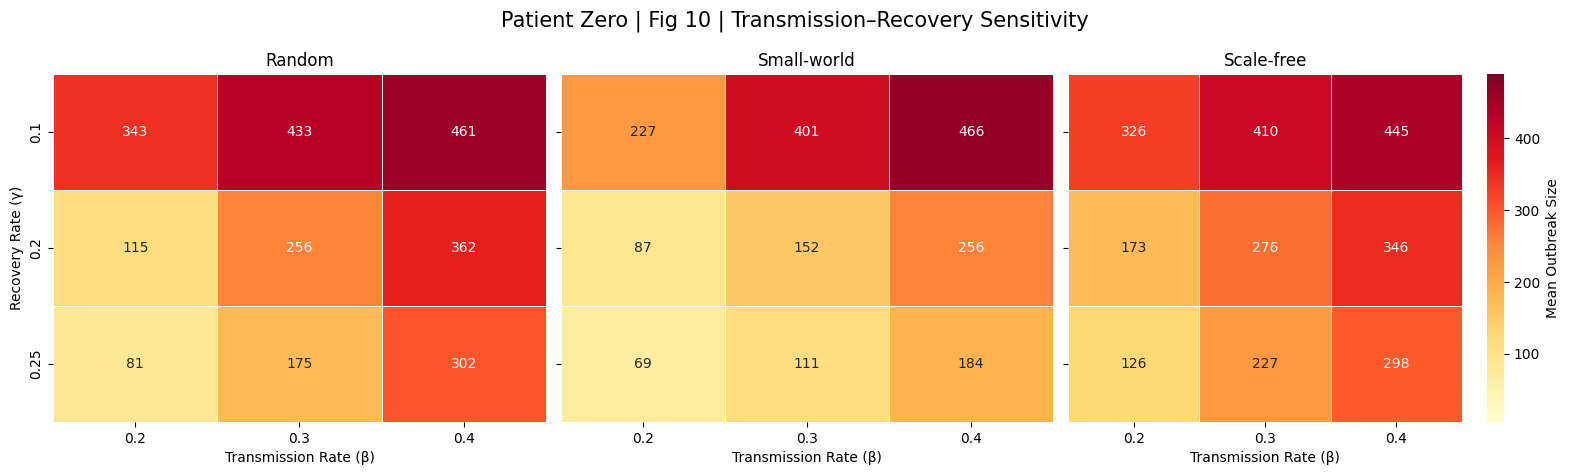

In [120]:
#viz - baseline (no vacc) - transmission and recovery sensitivity heatmap
fig,axes=plt.subplots(1,3,figsize=(16,4.8),sharey=True)

vmin=baseline_df["final_outbreak_size"].min()
vmax=baseline_df["final_outbreak_size"].max()

for ax, topology in zip(axes, topology_order):
    subset = baseline_df[baseline_df["topology"] == topology]

    heatmap_data = subset.pivot_table(index="gamma",columns="beta",values="final_outbreak_size",aggfunc="mean")

    sns.heatmap(heatmap_data,ax=ax,cmap="YlOrRd",vmin=vmin,vmax=vmax,annot=True,fmt=".0f",linewidths=0.5,cbar=(topology==topology_order[-1]),cbar_kws={"label":"Mean Outbreak Size"})

    ax.set_title(topology)
    ax.set_xlabel("Transmission Rate (β)")
    ax.set_ylabel("Recovery Rate (γ)" if ax==axes[0] else "")

fig.suptitle("Patient Zero | Fig 10 | Transmission–Recovery Sensitivity",fontsize=15)

plt.tight_layout()
plt.show()

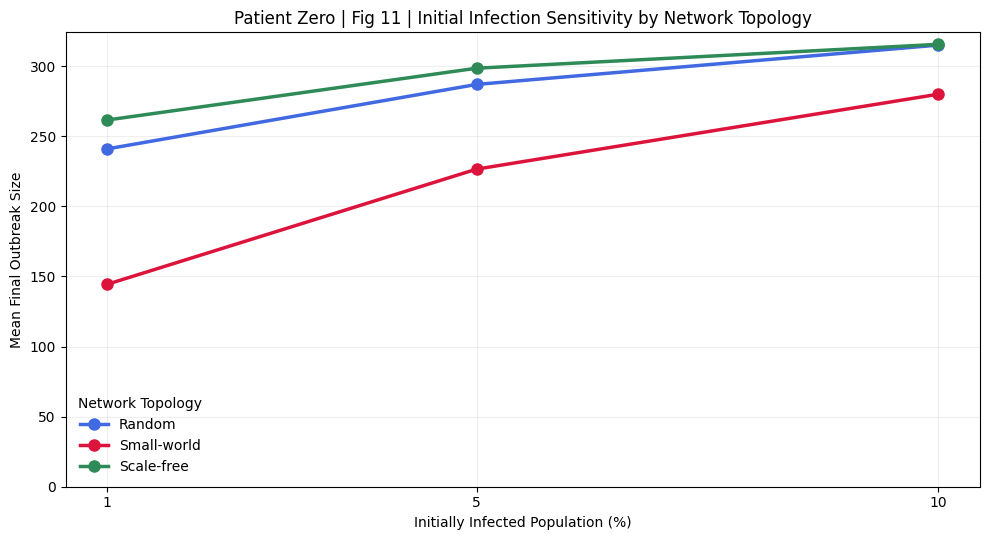

In [121]:
# viz - baseline (no vacc) - initial infection percentage and network topology
initial_infection_summary=(baseline_df.groupby(["topology","initial_infected_pct"],as_index=False).agg(
        mean_outbreak=("final_outbreak_size", "mean"),sd_outbreak=("final_outbreak_size", "std")))

fig,ax = plt.subplots(figsize=(10,5.5))

for topology in topology_order:
    subset=(initial_infection_summary[initial_infection_summary["topology"]==topology].sort_values("initial_infected_pct"))

    ax.plot(subset["initial_infected_pct"]*100,subset["mean_outbreak"],marker="o",linewidth=2.5,markersize=8,color=topology_colors[topology],label=topology)

ax.set_xlabel("Initially Infected Population (%)")
ax.set_ylabel("Mean Final Outbreak Size")
ax.set_xticks([1,5,10])
ax.set_ylim(bottom=0)
ax.set_title("Patient Zero | Fig 11 | Initial Infection Sensitivity by Network Topology")
ax.legend(title="Network Topology",frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [122]:
#baseline (no vacc) validation
assert len(baseline_df)==8100
assert baseline_df["scenario_id"].nunique()==81

assert (baseline_df.groupby("topology").size()==2700).all()
assert (baseline_df.groupby(["topology","initial_infected_pct","beta","gamma"]).size()==100).all()

assert len(initial_infection_summary)==9
assert not baseline_summary.isna().any().any()
assert not initial_infection_summary.isna().any().any()

print("Network topology analysis with no vaccinations (baseline) validation: PASSED")

Network topology analysis with no vaccinations (baseline) validation: PASSED


**Vaccination Effectiveness**

Each vaccinated scenario is matched to the unvaccinated scenario with the same topology, initial infected proportion, transmission rate and recovery rate. Let $\bar{O}_0$ and $\bar{O}_v$ be the corresponding mean outbreak sizes across repetitions. Absolute and percentage outbreak reductions are

$$
\Delta O=\bar{O}_0-\bar{O}_v
$$

$$
E=100\left(\frac{\bar{O}_0-\bar{O}_v}{\bar{O}_0}\right).
$$

Effectiveness is reported in percentage units. Each aggregate gives equal weight to the 27 scenario-specific percentage reductions for its topology, strategy and coverage. Fig 12 compares coverage responses, Fig 13 shows the distributions at 20% coverage alongside the corresponding baselines, and Fig 14 summarizes mean effectiveness in a heatmap. The largest separation between strategies is visible in the scale-free realization.

In [123]:
#vaccinated scenarios for respective unvaccinated scenarios
baseline_means=(scenario_summary.loc[scenario_summary["vaccination_strategy"]=="None",["comparison_id","mean_outbreak"]]
    .rename(columns={"mean_outbreak":"baseline_mean_outbreak"}))

vaccination_comparison_df=(scenario_summary.loc[scenario_summary["vaccination_strategy"]!="None"]
    .merge(baseline_means,on="comparison_id",how="left",validate="many_to_one"))

assert len(baseline_means)==81
assert len(vaccination_comparison_df)==486
assert vaccination_comparison_df["baseline_mean_outbreak"].notna().all()

display(vaccination_comparison_df.head())

,scenario_id,comparison_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage,mean_outbreak,sd_outbreak,median_outbreak,mean_peak,mean_peak_day,mean_duration,mean_attack_rate,repetitions,baseline_mean_outbreak
0,1,1,Random,0.01,0.2,0.1,Random,0.1,234.12,85.388983,261.0,42.51,53.18,142.84,0.46824,100,319.0
1,2,1,Random,0.01,0.2,0.1,Random,0.2,154.30,72.879796,177.5,26.92,51.69,138.80,0.30860,100,319.0
2,3,1,Random,0.01,0.2,0.1,Random,0.3,68.28,48.679965,65.5,14.86,33.38,94.98,0.13656,100,319.0
3,4,1,Random,0.01,0.2,0.1,Degree-Targeted,0.1,111.14,84.191343,112.5,19.41,44.73,123.49,0.22228,100,319.0
4,5,1,Random,0.01,0.2,0.1,Degree-Targeted,0.2,32.99,28.223314,23.0,9.75,17.73,65.24,0.06598,100,319.0


In [124]:
#vaccination effectiveness
vaccination_comparison_df["absolute_reduction"]=(vaccination_comparison_df["baseline_mean_outbreak"]-vaccination_comparison_df["mean_outbreak"])

vaccination_comparison_df["pct_reduction"]=(100*vaccination_comparison_df["absolute_reduction"]/vaccination_comparison_df["baseline_mean_outbreak"])

#avg across the 27 disease parameter combos
vaccination_effectiveness_summary=(vaccination_comparison_df.groupby(
        ["topology","vaccination_strategy","vaccination_coverage"],as_index=False)
    .agg(
        mean_pct_reduction=("pct_reduction","mean"),
        sd_pct_reduction=("pct_reduction","std"),
        mean_absolute_reduction=("absolute_reduction","mean"),
        mean_outbreak=("mean_outbreak","mean"),
        comparisons=("comparison_id","nunique")))

assert len(vaccination_effectiveness_summary)==18
assert (vaccination_effectiveness_summary["comparisons"]==27).all()

display(vaccination_effectiveness_summary.round(2))

,topology,vaccination_strategy,vaccination_coverage,mean_pct_reduction,sd_pct_reduction,mean_absolute_reduction,mean_outbreak,comparisons
0,Random,Degree-Targeted,0.1,39.54,16.50,99.75,181.18,27
1,Random,Degree-Targeted,0.2,61.44,16.78,166.75,114.19,27
2,Random,Degree-Targeted,0.3,72.50,13.84,205.22,75.72,27
3,Random,Random,0.1,21.84,8.65,55.27,225.66,27
4,Random,Random,0.2,39.84,13.10,105.42,175.51,27
5,Random,Random,0.3,54.49,14.22,149.49,131.45,27
6,Scale-free,Degree-Targeted,0.1,73.06,15.63,205.32,86.52,27
7,Scale-free,Degree-Targeted,0.2,83.21,10.37,242.21,49.63,27
8,Scale-free,Degree-Targeted,0.3,86.61,8.82,253.73,38.11,27
9,Scale-free,Random,0.1,18.86,6.42,50.32,241.52,27


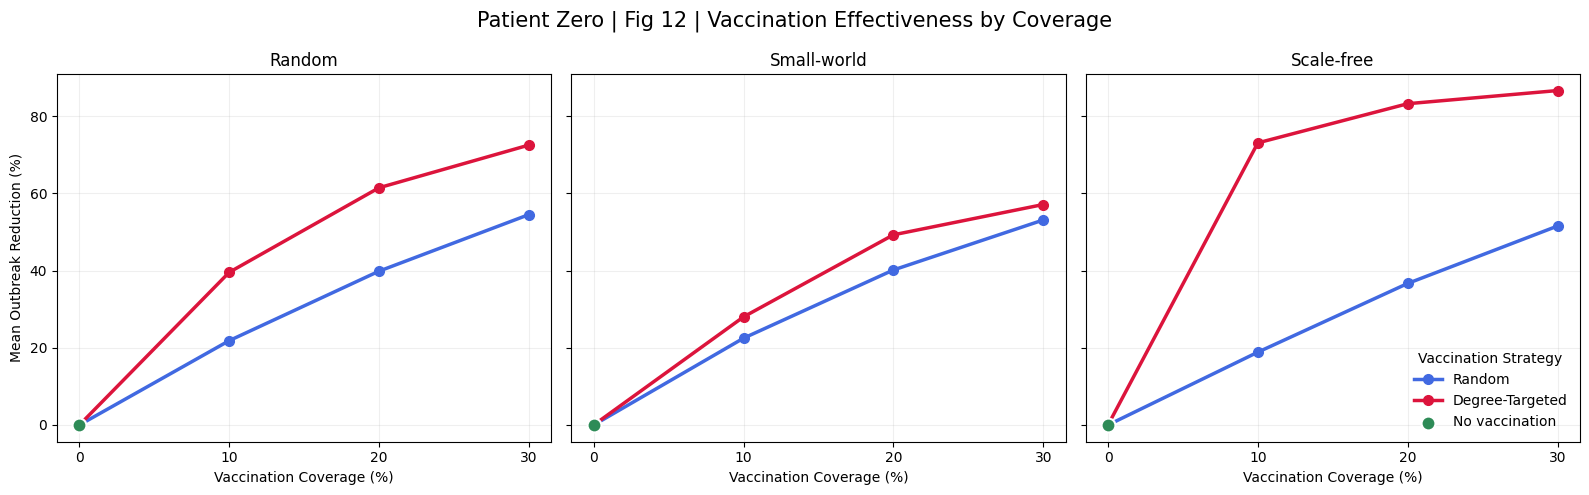

In [126]:
#viz - vaccination effectiveness across coverage levels
fig,axes=plt.subplots(1,3,figsize=(16,5),sharey=True)

strategy_order=["Random","Degree-Targeted"]

for ax,topology in zip(axes,topology_order):
    for strategy in strategy_order:
        subset = (
            vaccination_effectiveness_summary.loc[
                (vaccination_effectiveness_summary["topology"]==topology)
                & (vaccination_effectiveness_summary["vaccination_strategy"]==strategy)
            ]
            .sort_values("vaccination_coverage")
        )

        #shared no-vaccination baseline
        x=[0]+(subset["vaccination_coverage"]*100).tolist()
        y=[0]+subset["mean_pct_reduction"].tolist()

        ax.plot(x,y,marker="o",markersize=7,linewidth=2.5,color=vacc_colors[strategy],label=strategy)

    ax.scatter(0,0,color=vacc_colors["None"],s=100,edgecolor="white",linewidth=1.5,zorder=5,label="No vaccination")

    ax.set_title(topology)
    ax.set_xlabel("Vaccination Coverage (%)")
    ax.set_xticks([0,10,20,30])
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Mean Outbreak Reduction (%)")
axes[-1].legend(title="Vaccination Strategy",frameon=False)

fig.suptitle("Patient Zero | Fig 12 | Vaccination Effectiveness by Coverage",fontsize=15)

plt.tight_layout()
plt.show()

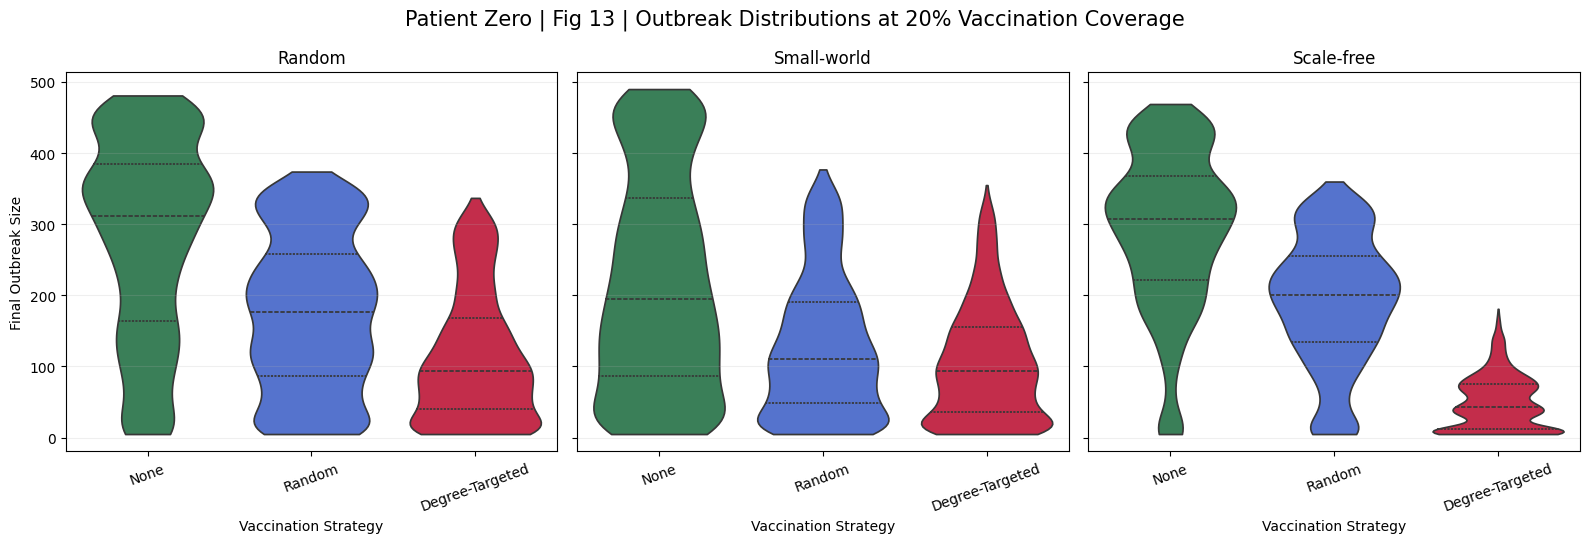

In [127]:
#viz - outbreak distributions by vaccination strategy
violin_df=mc_analysis_df.loc[
    (mc_analysis_df["vaccination_strategy"]=="None")
    | (
        (mc_analysis_df["vaccination_coverage"]==0.20)
        & (mc_analysis_df["vaccination_strategy"].isin(
            ["Random","Degree-Targeted"]
        ))
    )
].copy()

violin_order=["None","Random","Degree-Targeted"]

fig,axes=plt.subplots(1,3,figsize=(16,5.5),sharey=True)

for ax,topology in zip(axes,topology_order):
    subset=violin_df.loc[violin_df["topology"]==topology]

    sns.violinplot(data=subset,x="vaccination_strategy",y="final_outbreak_size",hue="vaccination_strategy",
        order=violin_order,hue_order=violin_order,palette=vacc_colors,inner="quartile",cut=0,legend=False,ax=ax)

    ax.set_title(topology)
    ax.set_xlabel("Vaccination Strategy")
    ax.tick_params(axis="x",labelrotation=20)
    ax.grid(axis="y",alpha=0.2)

axes[0].set_ylabel("Final Outbreak Size")

for ax in axes[1:]:
    ax.set_ylabel("")

fig.suptitle("Patient Zero | Fig 13 | Outbreak Distributions at 20% Vaccination Coverage",fontsize=15)

plt.tight_layout()
plt.show()

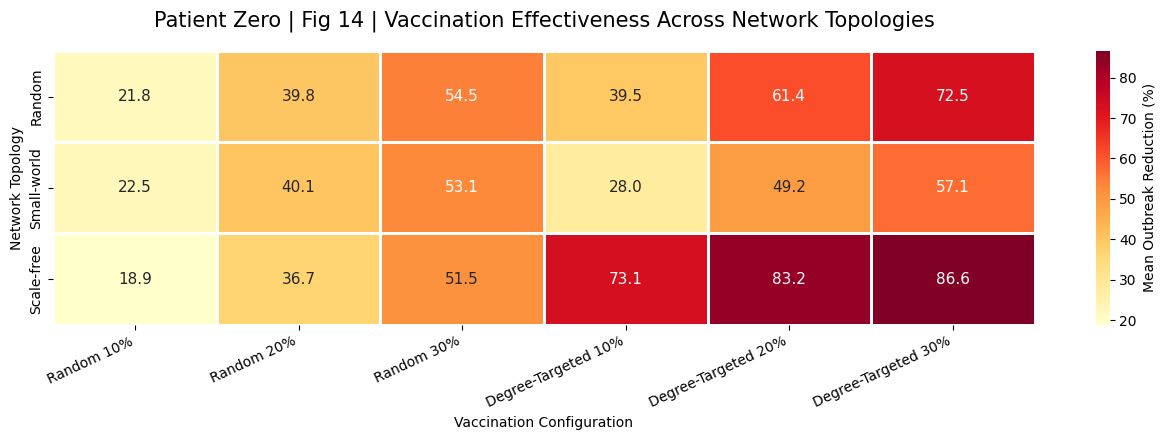

In [128]:
#viz - vaccination effectiveness heatmap
heatmap_df=vaccination_effectiveness_summary.copy()

heatmap_df["configuration"]=(heatmap_df["vaccination_strategy"]+" "
    +(heatmap_df["vaccination_coverage"]*100).round().astype(int).astype(str)
    +"%")

configuration_order=["Random 10%","Random 20%","Random 30%","Degree-Targeted 10%","Degree-Targeted 20%","Degree-Targeted 30%"]

heatmap_matrix=(heatmap_df.pivot(index="topology",columns="configuration",values="mean_pct_reduction")
    .reindex(index=topology_order, columns=configuration_order))

fig,ax=plt.subplots(figsize=(13,4.5))

sns.heatmap(heatmap_matrix,annot=True,fmt=".1f",cmap="YlOrRd",linewidths=1,linecolor="white",
    cbar_kws={"label": "Mean Outbreak Reduction (%)"},annot_kws={"fontsize": 11},ax=ax)

ax.set_title("Patient Zero | Fig 14 | Vaccination Effectiveness Across Network Topologies",pad=18,fontsize=15)

ax.set_xlabel("Vaccination Configuration")
ax.set_ylabel("Network Topology")
ax.set_xticklabels(ax.get_xticklabels(),rotation=25,ha="right")

plt.tight_layout()
plt.show()

In [130]:
# Validate vaccination effectiveness analysis
assert len(vaccination_comparison_df)==486
assert vaccination_comparison_df["scenario_id"].nunique()==486

assert (vaccination_comparison_df.groupby("comparison_id").size()==6).all()

assert len(vaccination_effectiveness_summary)==18
assert (vaccination_effectiveness_summary["comparisons"]==27).all()

assert heatmap_matrix.shape==(3,6)
assert heatmap_matrix.notna().all().all()

assert len(violin_df)==24300
assert (violin_df.groupby(["topology", "vaccination_strategy"]).size()==2700).all()

assert (vaccination_comparison_df["baseline_mean_outbreak"]>0).all()
assert vaccination_comparison_df["pct_reduction"].notna().all()

print("Vaccination effectiveness validation: PASSED")
print("Vaccinated scenarios analyzed:",len(vaccination_comparison_df))
print("Vaccination configurations:",len(vaccination_effectiveness_summary))
print("Violin plot observations:",len(violin_df))

Vaccination effectiveness validation: PASSED
Vaccinated scenarios analyzed: 486
Vaccination configurations: 18
Violin plot observations: 24300


**Statistical Inference & Uncertainty**

Comparisons pair outcomes by comparison and repetition identifiers. The stratified paired bootstrap resamples the 100 repetition pairs with replacement within each of the 27 epidemiological parameter combinations per topology. Each of 2,000 iterations recomputes the aggregate estimate. The 2.5th and 97.5th percentiles give the 95% confidence interval. Fig 15 presents these intervals for baseline-relative effectiveness, and Fig 16 presents them for the advantage of degree targeting.

At equal coverage, targeted vaccination advantage is

$$
A=\bar{O}_{\mathrm{random}}-\bar{O}_{\mathrm{targeted}}.
$$

Positive values measure additional infections prevented by degree-targeted vaccination. The one-sided paired sign-flip test asks whether mean paired differences favour targeting. Its null model assumes independent paired differences whose signs are exchangeable conditional on their magnitudes. For each of 10,000 permutations, the test flips signs independently and compares the permuted mean with the observed mean. The p-value uses a plus-one adjustment, and Holm correction controls family-wise error across the nine comparisons at a 0.05 threshold.

The aggregation sensitivity analysis compares the equal-weight mean of scenario-specific percentage reductions with a single percentage reduction computed from pooled means. The pooled estimate gives greater influence to scenarios with larger baseline means. The difference is measured in percentage points.

In [131]:
#matched strategy comparisons
strategy_means=(vaccination_comparison_df.pivot(
        index=["comparison_id","topology","initial_infected_pct","beta","gamma","vaccination_coverage"],
        columns="vaccination_strategy",values="mean_outbreak").reset_index())

strategy_means["targeted_advantage"]=(strategy_means["Random"]-strategy_means["Degree-Targeted"])

assert len(strategy_means)==243
assert strategy_means[["Random","Degree-Targeted"]].notna().all().all()

display(strategy_means.head())

vaccination_strategy,comparison_id,topology,initial_infected_pct,beta,gamma,vaccination_coverage,Degree-Targeted,Random,targeted_advantage
0,1,Random,0.01,0.2,0.1,0.1,111.14,234.12,122.98
1,1,Random,0.01,0.2,0.1,0.2,32.99,154.30,121.31
2,1,Random,0.01,0.2,0.1,0.3,17.83,68.28,50.45
3,2,Random,0.01,0.2,0.2,0.1,15.99,26.30,10.31
4,2,Random,0.01,0.2,0.2,0.2,10.88,17.64,6.76


In [132]:
#stratified bootstrapping
bootstrap_rng=np.random.default_rng(2026)
n_bootstrap=2000

bootstrap_records=[]

for topology in topology_order:
    topology_data=mc_analysis_df[mc_analysis_df["topology"]==topology]

    for coverage in [0.10,0.20,0.30]:
        for strategy in ["Random","Degree-Targeted"]:

            selected=topology_data[(
                    (topology_data["vaccination_strategy"] == strategy)
                    & (topology_data["vaccination_coverage"] == coverage))
                | (topology_data["vaccination_strategy"] == "None")]

            pivot=selected.pivot(
                index=["comparison_id", "repetition_id"],
                columns="vaccination_strategy",
                values="final_outbreak_size")

            baseline=pivot["None"].unstack("repetition_id").to_numpy()
            vaccinated=pivot[strategy].unstack("repetition_id").to_numpy()

            assert baseline.shape==(27,100)
            assert vaccinated.shape==(27,100)

            bootstrap_estimates=[]

            for _ in range(n_bootstrap):
                indices=bootstrap_rng.integers(0,100,size=(27,100))

                baseline_means=np.take_along_axis(baseline,indices,axis=1).mean(axis=1)

                vaccinated_means=np.take_along_axis(vaccinated,indices,axis=1).mean(axis=1)

                reductions=(100*(baseline_means-vaccinated_means)/baseline_means)

                bootstrap_estimates.append(reductions.mean())

            bootstrap_records.append({
                "topology":topology,
                "vaccination_strategy":strategy,
                "vaccination_coverage":coverage,
                "ci_lower":np.percentile(bootstrap_estimates,2.5),
                "ci_upper":np.percentile(bootstrap_estimates,97.5)})

vaccination_ci_df=pd.DataFrame(bootstrap_records)

vaccination_ci_df=vaccination_effectiveness_summary.merge(vaccination_ci_df,
    on=["topology","vaccination_strategy","vaccination_coverage"],validate="one_to_one")

display(vaccination_ci_df[["topology","vaccination_strategy","vaccination_coverage",
            "mean_pct_reduction","ci_lower","ci_upper"]].round(2))

,topology,vaccination_strategy,vaccination_coverage,mean_pct_reduction,ci_lower,ci_upper
0,Random,Degree-Targeted,0.1,39.54,38.62,40.31
1,Random,Degree-Targeted,0.2,61.44,60.88,61.91
2,Random,Degree-Targeted,0.3,72.50,71.99,72.88
3,Random,Random,0.1,21.84,20.49,22.91
4,Random,Random,0.2,39.84,38.88,40.70
5,Random,Random,0.3,54.49,53.69,55.17
6,Scale-free,Degree-Targeted,0.1,73.06,72.75,73.33
7,Scale-free,Degree-Targeted,0.2,83.21,83.04,83.36
8,Scale-free,Degree-Targeted,0.3,86.61,86.48,86.72
9,Scale-free,Random,0.1,18.86,17.77,19.84


In [133]:
#bootstrapping targeted vaccination advantage
strategy_bootstrap_records=[]

for topology in topology_order:
    for coverage in [0.10,0.20,0.30]:
        selected=mc_analysis_df.loc[
            (mc_analysis_df["topology"]==topology)
            & (mc_analysis_df["vaccination_coverage"]==coverage)
            & (mc_analysis_df["vaccination_strategy"].isin(
                ["Random","Degree-Targeted"]
            ))
        ]

        pivot = selected.pivot(index=["comparison_id","repetition_id"],
            columns="vaccination_strategy",values="final_outbreak_size")

        random_values=pivot["Random"].unstack("repetition_id").to_numpy()
        targeted_values=pivot["Degree-Targeted"].unstack("repetition_id").to_numpy()

        assert random_values.shape==targeted_values.shape==(27,100)

        observed_advantage=(random_values.mean(axis=1)-targeted_values.mean(axis=1)).mean()
        bootstrap_differences=np.empty(n_bootstrap)

        for b in range(n_bootstrap):
            indices=bootstrap_rng.integers(0,100,size=(27,100))

            random_means=np.take_along_axis(random_values,indices,axis=1).mean(axis=1)

            targeted_means=np.take_along_axis(targeted_values,indices,axis=1).mean(axis=1)

            bootstrap_differences[b]=(random_means-targeted_means).mean()

        strategy_bootstrap_records.append({
            "topology":topology,
            "vaccination_coverage":coverage,
            "targeted_advantage":observed_advantage,
            "ci_lower":np.percentile(bootstrap_differences,2.5),
            "ci_upper":np.percentile(bootstrap_differences,97.5)
        })

strategy_inference_df=pd.DataFrame(strategy_bootstrap_records)

display(strategy_inference_df.round(2))

,topology,vaccination_coverage,targeted_advantage,ci_lower,ci_upper
0,Random,0.1,44.48,42.43,46.38
1,Random,0.2,61.32,59.91,62.85
2,Random,0.3,55.73,54.54,56.94
3,Small-world,0.1,12.92,11.50,14.37
4,Small-world,0.2,23.61,22.47,24.81
5,Small-world,0.3,10.71,9.80,11.59
6,Scale-free,0.1,155.01,153.33,156.64
7,Scale-free,0.2,142.26,140.86,143.67
8,Scale-free,0.3,110.59,109.28,111.84


In [134]:
#paired sign-flip tests
n_permutations=10000
permutation_rng=np.random.default_rng(2037)

p_values=[]

for topology in topology_order:
    for coverage in [0.10,0.20,0.30]:

        selected=mc_analysis_df.loc[
            (mc_analysis_df["topology"]==topology)
            & (mc_analysis_df["vaccination_coverage"]==coverage)
            & (mc_analysis_df["vaccination_strategy"].isin(["Random","Degree-Targeted"]))]

        pivot = selected.pivot(index=["comparison_id","repetition_id"],
            columns="vaccination_strategy",values="final_outbreak_size")

        differences=(pivot["Random"]-pivot["Degree-Targeted"]).to_numpy()

        observed=differences.mean()

        extreme_count=0

        for _ in range(n_permutations):
            signs=permutation_rng.choice([-1,1],size=len(differences))
            permuted_mean=np.mean(differences*signs)

            if permuted_mean>=observed:
                extreme_count+=1

        p_values.append((extreme_count+1)/(n_permutations+1))

strategy_inference_df["p_value"]=p_values
strategy_inference_df["p_adjusted"]=multipletests(strategy_inference_df["p_value"],method="holm")[1]
strategy_inference_df["significant"]=(strategy_inference_df["p_adjusted"]<0.05)

display(strategy_inference_df.round(4))

,topology,vaccination_coverage,targeted_advantage,ci_lower,ci_upper,p_value,p_adjusted,significant
0,Random,0.1,44.4789,42.4310,46.3775,0.0001,0.0009,True
1,Random,0.2,61.3230,59.9136,62.8483,0.0001,0.0009,True
2,Random,0.3,55.7307,54.5384,56.9423,0.0001,0.0009,True
3,Small-world,0.1,12.9207,11.5009,14.3709,0.0001,0.0009,True
4,Small-world,0.2,23.6093,22.4722,24.8098,0.0001,0.0009,True
5,Small-world,0.3,10.7141,9.7966,11.5945,0.0001,0.0009,True
6,Scale-free,0.1,155.0067,153.3257,156.6430,0.0001,0.0009,True
7,Scale-free,0.2,142.2596,140.8600,143.6670,0.0001,0.0009,True
8,Scale-free,0.3,110.5948,109.2751,111.8448,0.0001,0.0009,True


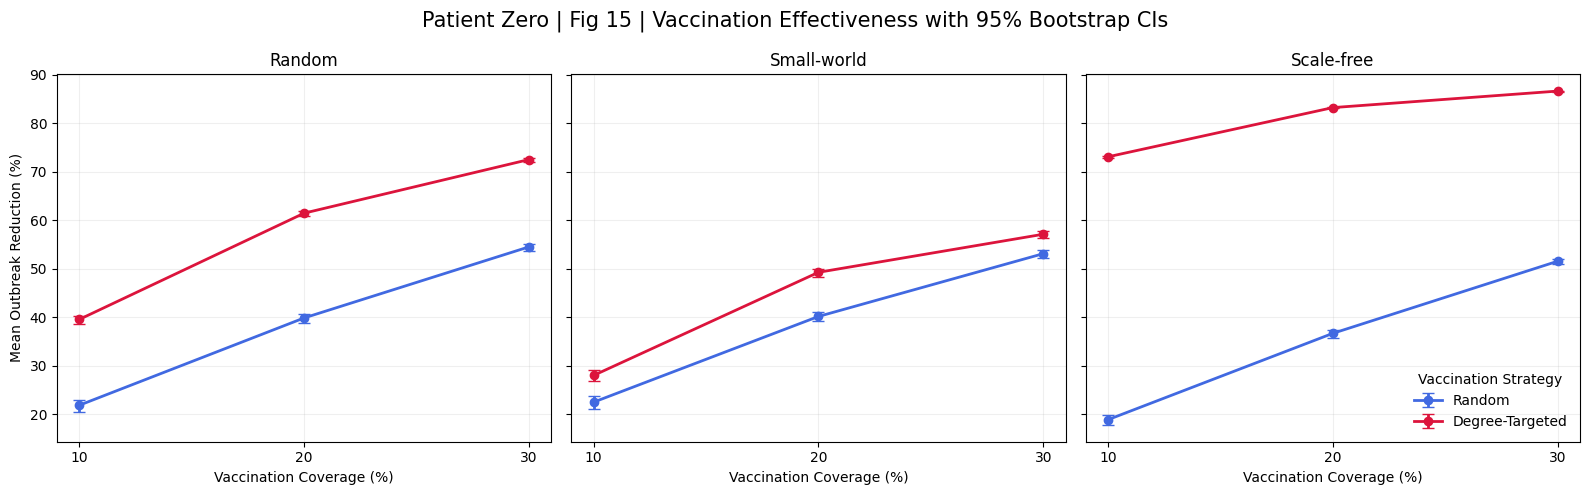

In [ ]:
#visualization - vaccination effectiveness with bootstrap CIs
fig,axes=plt.subplots(1,3,figsize=(16,5),sharey=True)

for ax, topology in zip(axes,topology_order):
    for strategy in ["Random","Degree-Targeted"]:

        subset = (
            vaccination_ci_df.loc[
                (vaccination_ci_df["topology"]==topology)
                & (vaccination_ci_df["vaccination_strategy"]==strategy)
            ]
            .sort_values("vaccination_coverage")
        )

        x=subset["vaccination_coverage"]*100
        y=subset["mean_pct_reduction"]

        yerr=np.vstack([y-subset["ci_lower"],subset["ci_upper"]-y])

        ax.errorbar(x,y,yerr=yerr,fmt="o-",capsize=4,linewidth=2,color=vacc_colors[strategy],label=strategy)

    ax.set_title(topology)
    ax.set_xlabel("Vaccination Coverage (%)")
    ax.set_xticks([10,20,30])
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Mean Outbreak Reduction (%)")
axes[-1].legend(title="Vaccination Strategy",frameon=False)

fig.suptitle("Patient Zero | Fig 15 | Vaccination Effectiveness with 95% Bootstrap CIs",fontsize=15)

plt.tight_layout()
plt.show()

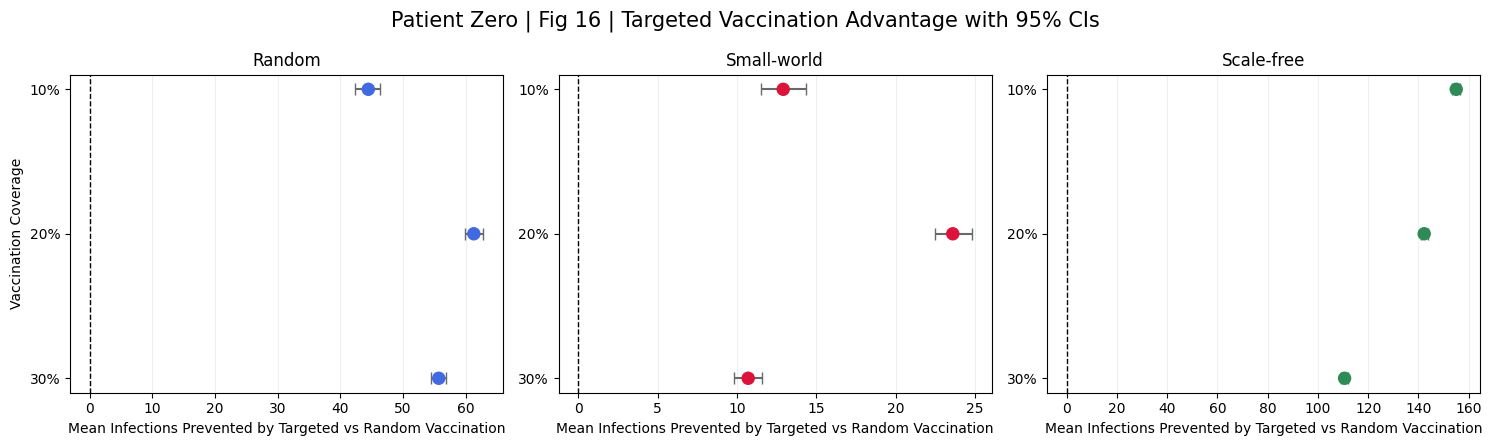

In [140]:
#viz - targeted vaccination advantage with CIs
fig,axes=plt.subplots(1,3,figsize=(15,4.5))

for ax,topology in zip(axes,topology_order):
    plot_df=strategy_inference_df[strategy_inference_df["topology"]==topology].sort_values("vaccination_coverage")
    positions=np.arange(len(plot_df))

    colors=[topology_colors[t]for t in plot_df["topology"]]

    xerr=np.vstack([plot_df["targeted_advantage"]-plot_df["ci_lower"],plot_df["ci_upper"]-plot_df["targeted_advantage"]])

    ax.errorbar(plot_df["targeted_advantage"],positions,xerr=xerr,fmt="none",ecolor="dimgray",capsize=4,linewidth=1.5)
    ax.scatter(plot_df["targeted_advantage"],positions,c=colors,s=75,zorder=3)

    ax.set_yticks(positions)
    ax.set_yticklabels(["10%","20%","30%"])
    ax.invert_yaxis()
    ax.axvline(0,color="black",linestyle="--",linewidth=1)
    ax.set_xlabel("Mean Infections Prevented by Targeted vs Random Vaccination")
    ax.set_title(topology,fontsize=12)
    ax.grid(axis="x",alpha=0.2)

axes[0].set_ylabel("Vaccination Coverage")
fig.suptitle("Patient Zero | Fig 16 | Targeted Vaccination Advantage with 95% CIs",fontsize=15)

plt.tight_layout()
plt.show()

In [141]:
#aggregation sensitivity
pooled_effectiveness=(vaccination_comparison_df.groupby(
        ["topology", "vaccination_strategy", "vaccination_coverage"],
        as_index=False)
    .agg(
        baseline_mean=("baseline_mean_outbreak", "mean"),
        vaccinated_mean=("mean_outbreak", "mean")
    ))

pooled_effectiveness["pooled_pct_reduction"]=(100*(
        pooled_effectiveness["baseline_mean"]
        - pooled_effectiveness["vaccinated_mean"])/pooled_effectiveness["baseline_mean"])

robustness_df=vaccination_effectiveness_summary.merge(pooled_effectiveness[[
            "topology",
            "vaccination_strategy",
            "vaccination_coverage",
            "pooled_pct_reduction"]],
    on=["topology", "vaccination_strategy","vaccination_coverage"],
    validate="one_to_one")

robustness_df["difference_pp"]=(robustness_df["mean_pct_reduction"]-robustness_df["pooled_pct_reduction"])

display(robustness_df[[
            "topology",
            "vaccination_strategy",
            "vaccination_coverage",
            "mean_pct_reduction",
            "pooled_pct_reduction",
            "difference_pp"]].round(2))

,topology,vaccination_strategy,vaccination_coverage,mean_pct_reduction,pooled_pct_reduction,difference_pp
0,Random,Degree-Targeted,0.1,39.54,35.51,4.03
1,Random,Degree-Targeted,0.2,61.44,59.35,2.09
2,Random,Degree-Targeted,0.3,72.50,73.05,-0.55
3,Random,Random,0.1,21.84,19.67,2.17
4,Random,Random,0.2,39.84,37.53,2.32
5,Random,Random,0.3,54.49,53.21,1.28
6,Scale-free,Degree-Targeted,0.1,73.06,70.36,2.71
7,Scale-free,Degree-Targeted,0.2,83.21,83.00,0.21
8,Scale-free,Degree-Targeted,0.3,86.61,86.94,-0.33
9,Scale-free,Random,0.1,18.86,17.24,1.62


In [142]:
#validation
assert len(vaccination_ci_df)==18
assert len(strategy_inference_df)==9
assert len(robustness_df)==18

assert (vaccination_ci_df["ci_lower"]<=vaccination_ci_df["mean_pct_reduction"]).all()
assert (vaccination_ci_df["mean_pct_reduction"]<=vaccination_ci_df["ci_upper"]).all()
assert (strategy_inference_df["ci_lower"]<=strategy_inference_df["targeted_advantage"]).all()
assert (strategy_inference_df["targeted_advantage"]<=strategy_inference_df["ci_upper"]).all()

assert strategy_inference_df["p_adjusted"].between(0,1).all()
assert robustness_df["difference_pp"].notna().all()

print("Statistical inference validation: PASSED")
print("Effectiveness estimates:",len(vaccination_ci_df))
print("Strategy comparisons:",len(strategy_inference_df))
print("Robustness comparisons:",len(robustness_df))

Statistical inference validation: PASSED
Effectiveness estimates: 18
Strategy comparisons: 9
Robustness comparisons: 18


**Research Findings**

The following tables consolidate the baseline summaries, vaccination effectiveness estimates and matched strategy comparisons that support the final interpretation.

In [144]:
#baseline epidemic outcomes by network topology
baseline_findings=(baseline_summary.loc[topology_order,[
            ("final_outbreak_size","mean"),
            ("peak_infected","mean"),
            ("duration","mean"),
            ("attack_rate","mean")]].copy())

baseline_findings.columns=["Mean Outbreak Size","Mean Peak Infections","Mean Duration","Mean Attack Rate"]

display(baseline_findings.round(2))

,Mean Outbreak Size,Mean Peak Infections,Mean Duration,Mean Attack Rate
topology,,,,
Random,280.94,78.05,71.40,0.56
Small-world,216.95,57.63,70.27,0.43
Scale-free,291.84,95.92,62.29,0.58


In [145]:
#vaccination effectiveness with 95% CIs
effectiveness_findings=vaccination_ci_df[["topology","vaccination_strategy","vaccination_coverage","mean_pct_reduction","ci_lower","ci_upper"]].copy()
effectiveness_findings=effectiveness_findings.sort_values(["topology", "vaccination_coverage", "vaccination_strategy"])

display(effectiveness_findings.round(2))

,topology,vaccination_strategy,vaccination_coverage,mean_pct_reduction,ci_lower,ci_upper
0,Random,Degree-Targeted,0.1,39.54,38.62,40.31
3,Random,Random,0.1,21.84,20.49,22.91
1,Random,Degree-Targeted,0.2,61.44,60.88,61.91
4,Random,Random,0.2,39.84,38.88,40.70
2,Random,Degree-Targeted,0.3,72.50,71.99,72.88
5,Random,Random,0.3,54.49,53.69,55.17
6,Scale-free,Degree-Targeted,0.1,73.06,72.75,73.33
9,Scale-free,Random,0.1,18.86,17.77,19.84
7,Scale-free,Degree-Targeted,0.2,83.21,83.04,83.36
10,Scale-free,Random,0.2,36.66,35.75,37.41


In [146]:
#additional infections prevented by targeted vaccination
strategy_findings=strategy_inference_df[["topology","vaccination_coverage","targeted_advantage","ci_lower","ci_upper","p_adjusted"]].copy()
strategy_findings=strategy_findings.sort_values(["topology", "vaccination_coverage"])

display(strategy_findings.round(3))

,topology,vaccination_coverage,targeted_advantage,ci_lower,ci_upper,p_adjusted
0,Random,0.1,44.479,42.431,46.378,0.001
1,Random,0.2,61.323,59.914,62.848,0.001
2,Random,0.3,55.731,54.538,56.942,0.001
6,Scale-free,0.1,155.007,153.326,156.643,0.001
7,Scale-free,0.2,142.260,140.860,143.667,0.001
8,Scale-free,0.3,110.595,109.275,111.845,0.001
3,Small-world,0.1,12.921,11.501,14.371,0.001
4,Small-world,0.2,23.609,22.472,24.810,0.001
5,Small-world,0.3,10.714,9.797,11.594,0.001


In [147]:
#validation
assert len(baseline_findings)==3
assert len(effectiveness_findings)==18
assert len(strategy_findings)==9

assert not baseline_findings.isna().any().any()
assert not effectiveness_findings.isna().any().any()
assert not strategy_findings.isna().any().any()

print("Research findings consolidation: PASSED")
print("Network topology summaries:",len(baseline_findings))
print("Vaccination effectiveness estimates:",len(effectiveness_findings))
print("Targeted vaccination comparisons:",len(strategy_findings))

Research findings consolidation: PASSED
Network topology summaries: 3
Vaccination effectiveness estimates: 18
Targeted vaccination comparisons: 9


<a name="notebook-visualization-tableau"></a>

### **Visualization & Tableau**

<a name="notebook-research-visualizations"></a>

##### *Research Visualizations*

The saved figures trace the analysis from deterministic compartment trajectories and network graphs through stochastic trajectories, outcome distributions, parameter sensitivity heatmaps and vaccination comparisons. Bootstrap confidence interval plots summarize the uncertainty in aggregate effectiveness and targeted vaccination advantage.

<a name="notebook-tableau-data-exports"></a>

##### *Tableau Data Exports*

The export pipeline transforms validated results into dashboard-ready datasets.

| Dataset | Rows | Purpose |
|---|---:|---|
| `scenario_summary.csv` | 567 | Scenario-level epidemic metrics |
| `simulation_results.csv` | 56,700 | Individual simulation outcomes |
| `vaccination_effectiveness.csv` | 18 | Aggregate effectiveness and confidence intervals |
| `strategy_comparison.csv` | 9 | Targeted vaccination advantage and statistical inference |

The aggregate confidence intervals represent the full epidemiological parameter grid for each topology and coverage. Recomputing intervals for a filtered parameter selection would require resampling the matching simulation records.

In [148]:
#export directory
tableau_dir=mc_output_dir.parent/"tableau"
tableau_dir.mkdir(parents=True,exist_ok=True)

print("Tableau export directory:",tableau_dir)

Tableau export directory: outputs\tableau


In [149]:
#scenario-level summary
scenario_tableau_df=(mc_analysis_df.groupby(
        [
            "scenario_id","comparison_id","topology",
            "initial_infected_pct","beta","gamma",
            "vaccination_strategy","vaccination_coverage"
        ],as_index=False
    ).agg(
        mean_outbreak_size=("final_outbreak_size","mean"),
        std_outbreak_size=("final_outbreak_size","std"),
        mean_peak_infected=("peak_infected","mean"),
        mean_peak_day=("peak_day","mean"),
        mean_duration=("duration","mean"),
        mean_attack_rate=("attack_rate","mean"),
        mean_vaccinated_count=("vaccinated_count","mean"),
        repetitions=("repetition_id","nunique")
    )
)

assert len(scenario_tableau_df)==567
assert (scenario_tableau_df["repetitions"]==100).all()

display(scenario_tableau_df.head())

,scenario_id,comparison_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage,mean_outbreak_size,std_outbreak_size,mean_peak_infected,mean_peak_day,mean_duration,mean_attack_rate,mean_vaccinated_count,repetitions
0,0,1,Random,0.01,0.2,0.1,None,0.0,319.00,83.671194,62.71,50.25,145.64,0.63800,0.0,100
1,1,1,Random,0.01,0.2,0.1,Random,0.1,234.12,85.388983,42.51,53.18,142.84,0.46824,50.0,100
2,2,1,Random,0.01,0.2,0.1,Random,0.2,154.30,72.879796,26.92,51.69,138.80,0.30860,100.0,100
3,3,1,Random,0.01,0.2,0.1,Random,0.3,68.28,48.679965,14.86,33.38,94.98,0.13656,150.0,100
4,4,1,Random,0.01,0.2,0.1,Degree-Targeted,0.1,111.14,84.191343,19.41,44.73,123.49,0.22228,50.0,100


In [150]:
#vaccination effectiveness with uncertainty
effectiveness_tableau_df=vaccination_ci_df.copy()

#targeted vs random strategies
strategy_tableau_df=strategy_inference_df.copy()

#full simulation-level dataset
simulation_tableau_df=mc_analysis_df.copy()

#vaccination labels consistency check
for df in [effectiveness_tableau_df,strategy_tableau_df,simulation_tableau_df]:
    if "vaccination_strategy" in df.columns:
        df["vaccination_strategy"]=(df["vaccination_strategy"].fillna("None"))

print("Effectiveness:",effectiveness_tableau_df.shape)
print("Strategy comparisons:",strategy_tableau_df.shape)
print("Simulation results:",simulation_tableau_df.shape)

Effectiveness: (18, 10)
Strategy comparisons: (9, 8)
Simulation results: (56700, 16)


In [151]:
#exports
tableau_exports={
    "scenario_summary.csv": scenario_tableau_df,
    "vaccination_effectiveness.csv": effectiveness_tableau_df,
    "strategy_comparison.csv": strategy_tableau_df,
    "simulation_results.csv": simulation_tableau_df
}

for filename,df in tableau_exports.items():
    export_path=tableau_dir/filename
    df.to_csv(export_path,index=False)

    print(f"Exported {filename}: {len(df):,} rows")

Exported scenario_summary.csv: 567 rows
Exported vaccination_effectiveness.csv: 18 rows
Exported strategy_comparison.csv: 9 rows
Exported simulation_results.csv: 56,700 rows


In [154]:
#reload exports
tableau_loaded = {filename:pd.read_csv(tableau_dir/filename,keep_default_na=False) for filename in tableau_exports}

expected_rows={
    "scenario_summary.csv":567,
    "vaccination_effectiveness.csv":18,
    "strategy_comparison.csv":9,
    "simulation_results.csv":56_700
}

# Validate dimensions, columns, and missing values
for filename,df in tableau_loaded.items():
    original=tableau_exports[filename]

    assert len(df)==expected_rows[filename],f"Row count mismatch: {filename}"
    assert list(df.columns)==list(original.columns),f"Column mismatch: {filename}"
    assert not df.columns.duplicated().any(),f"Duplicate columns: {filename}"
    assert not df.isna().any().any(),f"Missing values: {filename}"

    print(f"PASS | {filename}: {len(df):,} rows")

print("\nCSV integrity: PASSED")

PASS | scenario_summary.csv: 567 rows
PASS | vaccination_effectiveness.csv: 18 rows
PASS | strategy_comparison.csv: 9 rows
PASS | simulation_results.csv: 56,700 rows

CSV integrity: PASSED


In [155]:
#simulation-level integrity
sim=tableau_loaded["simulation_results.csv"]
scenarios=tableau_loaded["scenario_summary.csv"]

assert sim["scenario_id"].nunique()==567
assert sim["comparison_id"].nunique()==81
assert sim["repetition_id"].nunique()==100

assert not sim.duplicated(subset=["scenario_id","repetition_id"]).any()

assert (sim.groupby("scenario_id").size()==100).all()
assert sim["completed"].astype(str).str.lower().eq("true").all()

#scenario-level integrity
assert scenarios["scenario_id"].is_unique
assert scenarios["comparison_id"].nunique()==81
assert (scenarios["repetitions"]==100).all()

assert set(sim["topology"])=={"Random","Small-world","Scale-free"}

assert set(sim["vaccination_strategy"])=={"None","Random","Degree-Targeted"}

#outbreak metrics
assert sim["final_outbreak_size"].between(0,500).all()
assert sim["peak_infected"].between(0,500).all()
assert sim["attack_rate"].between(0,1).all()
assert sim["vaccination_coverage"].between(0,1).all()

#statistical comparison tables
effectiveness=tableau_loaded["vaccination_effectiveness.csv"]
strategy=tableau_loaded["strategy_comparison.csv"]

assert len(effectiveness)==18
assert len(strategy)==9

print("Experimental coverage: PASSED")
print("Simulation uniqueness: PASSED")
print("Outbreak metrics: PASSED")
print("Statistical table dimensions: PASSED")

Experimental coverage: PASSED
Simulation uniqueness: PASSED
Outbreak metrics: PASSED
Statistical table dimensions: PASSED


In [156]:
#comparing exported CSVs against source DataFrames
for filename,original in tableau_exports.items():
    reloaded=tableau_loaded[filename]

    pd.testing.assert_frame_equal(
        reloaded,
        original.reset_index(drop=True),
        check_dtype=False,
        check_exact=False,
        rtol=1e-9,
        atol=1e-10
    )

    print(f"PASS | Values verified: {filename}")

print("\nFinal Tableau export validation: PASSED")

PASS | Values verified: scenario_summary.csv
PASS | Values verified: vaccination_effectiveness.csv
PASS | Values verified: strategy_comparison.csv
PASS | Values verified: simulation_results.csv

Final Tableau export validation: PASSED


**Dashboard Data Refinement**

The detailed effectiveness export, `vaccination_effectiveness_detailed.csv`, contains 486 vaccinated scenarios. The `strategy_comparison_detailed.csv` export contains 243 matched random versus degree-targeted comparisons. Both retain initial infection, transmission and recovery parameters to support filtering in Tableau.

In [158]:
#detailed vaccination effectiveness by experimental comparison group
keys=["comparison_id","topology","initial_infected_pct","beta","gamma"]

baseline=scenario_tableau_df[scenario_tableau_df["vaccination_strategy"]=="None"][keys+["mean_outbreak_size"]]
baseline=baseline.rename(columns={"mean_outbreak_size":"baseline_mean_outbreak"})

effectiveness_detailed=scenario_tableau_df[
    scenario_tableau_df["vaccination_strategy"].isin(["Random","Degree-Targeted"])
].merge(baseline,on=keys,how="left",validate="many_to_one")

effectiveness_detailed["absolute_reduction"]=effectiveness_detailed["baseline_mean_outbreak"]-effectiveness_detailed["mean_outbreak_size"]
effectiveness_detailed["pct_reduction"]=100*effectiveness_detailed["absolute_reduction"]/effectiveness_detailed["baseline_mean_outbreak"]

effectiveness_detailed=effectiveness_detailed.rename(columns={"mean_outbreak_size":"vaccinated_mean_outbreak"})

assert len(effectiveness_detailed)==486
assert effectiveness_detailed["baseline_mean_outbreak"].gt(0).all()
assert effectiveness_detailed["pct_reduction"].notna().all()

print("Detailed effectiveness:",effectiveness_detailed.shape)
display(effectiveness_detailed.head())

Detailed effectiveness: (486, 19)


,scenario_id,comparison_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage,vaccinated_mean_outbreak,std_outbreak_size,mean_peak_infected,mean_peak_day,mean_duration,mean_attack_rate,mean_vaccinated_count,repetitions,baseline_mean_outbreak,absolute_reduction,pct_reduction
0,1,1,Random,0.01,0.2,0.1,Random,0.1,234.12,85.388983,42.51,53.18,142.84,0.46824,50.0,100,319.0,84.88,26.608150
1,2,1,Random,0.01,0.2,0.1,Random,0.2,154.30,72.879796,26.92,51.69,138.80,0.30860,100.0,100,319.0,164.70,51.630094
2,3,1,Random,0.01,0.2,0.1,Random,0.3,68.28,48.679965,14.86,33.38,94.98,0.13656,150.0,100,319.0,250.72,78.595611
3,4,1,Random,0.01,0.2,0.1,Degree-Targeted,0.1,111.14,84.191343,19.41,44.73,123.49,0.22228,50.0,100,319.0,207.86,65.159875
4,5,1,Random,0.01,0.2,0.1,Degree-Targeted,0.2,32.99,28.223314,9.75,17.73,65.24,0.06598,100.0,100,319.0,286.01,89.658307


In [159]:
#detailed degree-targeted vs random vaccination comparison
strategy_detailed=effectiveness_detailed.pivot(
    index=keys+["vaccination_coverage"],
    columns="vaccination_strategy",
    values="vaccinated_mean_outbreak"
).reset_index()

strategy_detailed.columns.name=None
strategy_detailed=strategy_detailed.rename(columns={
    "Random":"random_mean_outbreak",
    "Degree-Targeted":"targeted_mean_outbreak"
})

strategy_detailed["targeted_advantage"]=strategy_detailed["random_mean_outbreak"]-strategy_detailed["targeted_mean_outbreak"]

assert len(strategy_detailed)==243
assert strategy_detailed[["random_mean_outbreak","targeted_mean_outbreak","targeted_advantage"]].notna().all().all()

print("Detailed strategy comparisons:",strategy_detailed.shape)
display(strategy_detailed.head())

Detailed strategy comparisons: (243, 9)


,comparison_id,topology,initial_infected_pct,beta,gamma,vaccination_coverage,targeted_mean_outbreak,random_mean_outbreak,targeted_advantage
0,1,Random,0.01,0.2,0.1,0.1,111.14,234.12,122.98
1,1,Random,0.01,0.2,0.1,0.2,32.99,154.30,121.31
2,1,Random,0.01,0.2,0.1,0.3,17.83,68.28,50.45
3,2,Random,0.01,0.2,0.2,0.1,15.99,26.30,10.31
4,2,Random,0.01,0.2,0.2,0.2,10.88,17.64,6.76


In [160]:
#validation
assert effectiveness_detailed["comparison_id"].nunique()==81
assert strategy_detailed["comparison_id"].nunique()==81

assert (effectiveness_detailed.groupby("comparison_id").size()==6).all()
assert (strategy_detailed.groupby("comparison_id").size()==3).all()

assert not effectiveness_detailed.duplicated(keys+["vaccination_strategy","vaccination_coverage"]).any()
assert not strategy_detailed.duplicated(keys+["vaccination_coverage"]).any()

assert (effectiveness_detailed["repetitions"]==100).all()
assert effectiveness_detailed["pct_reduction"].le(100).all()

print("Detailed comparison coverage: PASSED")
print("Unique experimental groups: PASSED")
print("Baseline-relative calculations: PASSED")

Detailed comparison coverage: PASSED
Unique experimental groups: PASSED
Baseline-relative calculations: PASSED


In [161]:
#export new datasets
refined_exports={
    "vaccination_effectiveness_detailed.csv":effectiveness_detailed,
    "strategy_comparison_detailed.csv":strategy_detailed
}

for filename,df in refined_exports.items():
    df.to_csv(tableau_dir/filename,index=False)
    reloaded=pd.read_csv(tableau_dir/filename,keep_default_na=False)
    pd.testing.assert_frame_equal(reloaded,df.reset_index(drop=True),check_dtype=False,check_exact=False,rtol=1e-9,atol=1e-10)
    print(f"PASS | {filename}: {len(reloaded):,} rows")

print("\nDetailed Tableau exports: PASSED")

PASS | vaccination_effectiveness_detailed.csv: 486 rows
PASS | strategy_comparison_detailed.csv: 243 rows

Detailed Tableau exports: PASSED


**Violin Plot Geometry**

Gaussian kernel density estimation smooths each scenario's outbreak size distribution over 101 grid points. Densities are normalized to their scenario maximum for display width. A constant-outcome scenario is represented by a single nonzero grid point. The polygon mirrors the normalized widths and orders vertices along one side and back along the other.

The exports contain 57,267 rows in `violin_density.csv`, 114,534 in `violin_polygons.csv` and 147,258 in `violin_comparison.csv`. The comparison export associates the same unvaccinated baseline with each coverage selection for the matching epidemiological parameters. This association is a display convention. Selecting multiple parameter combinations displays precomputed scenario shapes. A pooled density would require a new estimate from the underlying outcomes.

In [ ]:
#recorded simulation outcomes
violin_source=mc_analysis_df.copy() if "mc_analysis_df" in globals() else pd.read_csv(tableau_dir/"simulation_results.csv",keep_default_na=False)

violin_source["vaccination_strategy"]=violin_source["vaccination_strategy"].fillna("None").replace({"":"None"})

#KDE coordinates for every scenario
density_rows=[]
y_grid=np.linspace(0,500,101)

for scenario_id,group in violin_source.groupby("scenario_id"):
    values=group["final_outbreak_size"].to_numpy(dtype=float)

    if np.std(values)>0:
        kde=gaussian_kde(values)
        density=kde(y_grid)
    else:
        density=np.zeros_like(y_grid)
        density[np.argmin(abs(y_grid-values[0]))]=1

    density=density/density.max() if density.max()>0 else density

    metadata=group.iloc[0]

    for y,d in zip(y_grid,density):
        density_rows.append({
            "scenario_id":scenario_id,
            "comparison_id":metadata["comparison_id"],
            "topology":metadata["topology"],
            "initial_infected_pct":metadata["initial_infected_pct"],
            "beta":metadata["beta"],
            "gamma":metadata["gamma"],
            "vaccination_strategy":metadata["vaccination_strategy"],
            "vaccination_coverage":metadata["vaccination_coverage"],
            "outbreak_size":y,
            "density":d,
            "left_width":-d,
            "right_width":d
        })

violin_density=pd.DataFrame(density_rows)

print("Violin density dataset:",violin_density.shape)
display(violin_density.head())

Violin density dataset: (57267, 12)


,scenario_id,comparison_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage,outbreak_size,density,left_width,right_width
0,0,1,Random,0.01,0.2,0.1,None,0.0,0.0,0.080576,-0.080576,0.080576
1,0,1,Random,0.01,0.2,0.1,None,0.0,5.0,0.083028,-0.083028,0.083028
2,0,1,Random,0.01,0.2,0.1,None,0.0,10.0,0.083682,-0.083682,0.083682
3,0,1,Random,0.01,0.2,0.1,None,0.0,15.0,0.082497,-0.082497,0.082497
4,0,1,Random,0.01,0.2,0.1,None,0.0,20.0,0.079551,-0.079551,0.079551


In [164]:
assert violin_density["scenario_id"].nunique()==567
assert len(violin_density)==567*101
assert (violin_density.groupby("scenario_id").size()==101).all()
assert violin_density["density"].between(0,1).all()
assert violin_density["outbreak_size"].between(0,500).all()
assert not violin_density.isna().any().any()

print("Violin density validation: PASSED")

Violin density validation: PASSED


In [165]:
violin_path=tableau_dir/"violin_density.csv"
violin_density.to_csv(violin_path,index=False)

reloaded=pd.read_csv(violin_path,keep_default_na=False)
pd.testing.assert_frame_equal(reloaded,violin_density.reset_index(drop=True),check_dtype=False,check_exact=False,rtol=1e-9,atol=1e-10)

print(f"Exported {violin_path.name}: {len(reloaded):,} rows")
print("Violin density export: PASSED")

Exported violin_density.csv: 57,267 rows
Violin density export: PASSED


In [ ]:
#symmetrical violin polygons
polygon_rows=[]

for scenario_id,group in violin_density.groupby("scenario_id",sort=False):
    group=group.sort_values("outbreak_size")
    metadata=group.iloc[0].to_dict()

    #right boundary: bottom to top
    right=group[["outbreak_size","right_width"]].rename(columns={"right_width":"violin_x"})
    right["path_order"]=np.arange(len(right))

    #left boundary: top to bottom
    left=group[["outbreak_size","left_width"]].iloc[::-1].rename(columns={"left_width":"violin_x"})
    left["path_order"]=np.arange(len(right),len(right)+len(left))

    polygon=pd.concat([right,left],ignore_index=True)

    for column in ["scenario_id","comparison_id","topology","initial_infected_pct","beta","gamma","vaccination_strategy","vaccination_coverage"]:
        polygon[column]=metadata[column]

    polygon_rows.append(polygon)

violin_polygons=pd.concat(polygon_rows,ignore_index=True)

print("Violin polygon dataset:",violin_polygons.shape)
display(violin_polygons.head())

Violin polygon dataset: (114534, 11)


,outbreak_size,violin_x,path_order,scenario_id,comparison_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage
0,0.0,0.080576,0,0,1,Random,0.01,0.2,0.1,None,0.0
1,5.0,0.083028,1,0,1,Random,0.01,0.2,0.1,None,0.0
2,10.0,0.083682,2,0,1,Random,0.01,0.2,0.1,None,0.0
3,15.0,0.082497,3,0,1,Random,0.01,0.2,0.1,None,0.0
4,20.0,0.079551,4,0,1,Random,0.01,0.2,0.1,None,0.0


In [167]:
#validation
assert violin_polygons["scenario_id"].nunique()==567
assert len(violin_polygons)==567*202
assert (violin_polygons.groupby("scenario_id").size()==202).all()
assert (violin_polygons.groupby("scenario_id")["path_order"].nunique()==202).all()
assert violin_polygons["violin_x"].between(-1,1).all()
assert violin_polygons["outbreak_size"].between(0,500).all()
assert not violin_polygons.isna().any().any()

#export for Tableau
polygon_path=tableau_dir/"violin_polygons.csv"
violin_polygons.to_csv(polygon_path,index=False)

reloaded=pd.read_csv(polygon_path,keep_default_na=False)
pd.testing.assert_frame_equal(reloaded,violin_polygons.reset_index(drop=True),check_dtype=False,check_exact=False,rtol=1e-9,atol=1e-10)

print(f"Exported {polygon_path.name}: {len(reloaded):,} rows")
print("Violin polygon validation: PASSED")

Exported violin_polygons.csv: 114,534 rows
Violin polygon validation: PASSED


In [168]:
#final Tableau violin polygons: matched vaccination comparisons
from scipy.stats import gaussian_kde

sim=mc_analysis_df.copy() if "mc_analysis_df" in globals() else pd.read_csv(tableau_dir/"simulation_results.csv",keep_default_na=False)
sim["vaccination_strategy"]=sim["vaccination_strategy"].fillna("None").replace({"":"None"})

y_grid=np.linspace(0,500,101)
violin_rows=[]
group_cols=["topology","initial_infected_pct","beta","gamma"]

for keys,group in sim.groupby(group_cols,sort=False):
    baseline=group[group["vaccination_strategy"]=="None"]

    for coverage in [0.1,0.2,0.3]:
        for strategy in ["None","Random","Degree-Targeted"]:
            subset=baseline if strategy=="None" else group[(group["vaccination_strategy"]==strategy)&(np.isclose(group["vaccination_coverage"],coverage))]
            values=subset["final_outbreak_size"].to_numpy(dtype=float)

            assert len(values)==100,f"Unexpected sample size: {keys},{coverage},{strategy}"

            if np.std(values)>0:
                density=gaussian_kde(values)(y_grid)
            else:
                density=np.zeros_like(y_grid)
                density[np.argmin(abs(y_grid-values[0]))]=1

            density=density/density.max() if density.max()>0 else density

            x=np.concatenate([density,-density[::-1]])
            y=np.concatenate([y_grid,y_grid[::-1]])

            for order,(x_value,y_value) in enumerate(zip(x,y)):
                violin_rows.append({
                    "topology":keys[0],
                    "initial_infected_pct":keys[1],
                    "beta":keys[2],
                    "gamma":keys[3],
                    "vaccination_strategy":strategy,
                    "vaccination_coverage":coverage,
                    "outbreak_size":y_value,
                    "violin_x":x_value,
                    "path_order":order
                })

violin_final=pd.DataFrame(violin_rows)

print("Final violin dataset:",violin_final.shape)
display(violin_final.head())

Final violin dataset: (147258, 9)


,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage,outbreak_size,violin_x,path_order
0,Random,0.01,0.2,0.1,None,0.1,0.0,0.080576,0
1,Random,0.01,0.2,0.1,None,0.1,5.0,0.083028,1
2,Random,0.01,0.2,0.1,None,0.1,10.0,0.083682,2
3,Random,0.01,0.2,0.1,None,0.1,15.0,0.082497,3
4,Random,0.01,0.2,0.1,None,0.1,20.0,0.079551,4


In [169]:
#validation
violin_keys=group_cols+["vaccination_strategy","vaccination_coverage"]

assert len(violin_final)==81*3*3*202
assert violin_final.groupby(violin_keys).ngroups==729
assert (violin_final.groupby(violin_keys).size()==202).all()
assert (violin_final.groupby(violin_keys)["path_order"].nunique()==202).all()
assert violin_final["violin_x"].between(-1,1).all()
assert violin_final["outbreak_size"].between(0,500).all()
assert not violin_final.isna().any().any()

violin_final_path=tableau_dir/"violin_comparison.csv"
violin_final.to_csv(violin_final_path,index=False)

reloaded=pd.read_csv(violin_final_path,keep_default_na=False)
pd.testing.assert_frame_equal(reloaded,violin_final.reset_index(drop=True),check_dtype=False,check_exact=False,rtol=1e-9,atol=1e-10)

print(f"Exported {violin_final_path.name}: {len(reloaded):,} rows")
print("Final violin comparison validation: PASSED")

Exported violin_comparison.csv: 147,258 rows
Final violin comparison validation: PASSED


**Radial Visualization Geometry**

The radial export gives each of the 567 scenarios a fixed angular position and uses sine and cosine to place four ordered vertices per scenario, for 2,268 rows in `radial_outbreak.csv`. Radial length encodes the percentage reduction relative to the matched baseline. The geometry clips lengths to the 0–100% range, and the export retains the underlying percentage. Angular positions index sorted scenarios and have no temporal or geographical meaning.

In [171]:
radial_source=pd.read_csv(tableau_dir/"scenario_summary.csv",keep_default_na=False)
radial_source["vaccination_strategy"]=radial_source["vaccination_strategy"].fillna("None").replace({"":"None"})

print("Dataset shape:",radial_source.shape)
print("Columns:",radial_source.columns.tolist())

#match each scenario to its unvaccinated baseline
baseline=radial_source[radial_source["vaccination_strategy"]=="None"][["comparison_id","mean_outbreak_size"]].rename(columns={"mean_outbreak_size":"baseline_outbreak_size"})
radial_source=radial_source.merge(baseline,on="comparison_id",how="left",validate="many_to_one")

assert radial_source["baseline_outbreak_size"].notna().all()
assert (radial_source["baseline_outbreak_size"]>0).all()

radial_source["pct_reduction"]=100*(radial_source["baseline_outbreak_size"]-radial_source["mean_outbreak_size"])/radial_source["baseline_outbreak_size"]
radial_source.loc[radial_source["vaccination_strategy"]=="None","pct_reduction"]=0

#assign fixed angular positions to all 567 scenarios
radial_source=radial_source.sort_values(["topology","initial_infected_pct","beta","gamma","vaccination_coverage","vaccination_strategy"]).reset_index(drop=True)
radial_source["bar_index"]=np.arange(len(radial_source))

#generate radial polygon geometry
radial_rows=[]
total_bars=len(radial_source)
inner_radius=1.0
max_bar_length=0.9
bar_gap=0.18

for _,scenario in radial_source.iterrows():
    angle_center=2*np.pi*scenario["bar_index"]/total_bars
    half_width=np.pi*(1-bar_gap)/total_bars
    angle_left=angle_center-half_width
    angle_right=angle_center+half_width

    outer_radius=inner_radius+max_bar_length*np.clip(scenario["pct_reduction"],0,100)/100

    corners=[
        (inner_radius*np.cos(angle_left),inner_radius*np.sin(angle_left)),
        (outer_radius*np.cos(angle_left),outer_radius*np.sin(angle_left)),
        (outer_radius*np.cos(angle_right),outer_radius*np.sin(angle_right)),
        (inner_radius*np.cos(angle_right),inner_radius*np.sin(angle_right))
    ]

    for path_order,(x,y) in enumerate(corners):
        radial_rows.append({
            "scenario_id":scenario["scenario_id"],
            "topology":scenario["topology"],
            "initial_infected_pct":scenario["initial_infected_pct"],
            "beta":scenario["beta"],
            "gamma":scenario["gamma"],
            "vaccination_strategy":scenario["vaccination_strategy"],
            "vaccination_coverage":scenario["vaccination_coverage"],
            "mean_outbreak_size":scenario["mean_outbreak_size"],
            "baseline_outbreak_size":scenario["baseline_outbreak_size"],
            "pct_reduction":scenario["pct_reduction"],
            "bar_index":scenario["bar_index"],
            "path_order":path_order,
            "radial_x":x,
            "radial_y":y
        })

radial_outbreak=pd.DataFrame(radial_rows)

print("Radial dataset:",radial_outbreak.shape)
display(radial_outbreak.head())

Dataset shape: (567, 16)
Columns: ['scenario_id', 'comparison_id', 'topology', 'initial_infected_pct', 'beta', 'gamma', 'vaccination_strategy', 'vaccination_coverage', 'mean_outbreak_size', 'std_outbreak_size', 'mean_peak_infected', 'mean_peak_day', 'mean_duration', 'mean_attack_rate', 'mean_vaccinated_count', 'repetitions']
Radial dataset: (2268, 14)


,scenario_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage,mean_outbreak_size,baseline_outbreak_size,pct_reduction,bar_index,path_order,radial_x,radial_y
0,0,Random,0.01,0.2,0.1,None,0.0,319.00,319.0,0.000000,0,0,0.999990,-0.004543
1,0,Random,0.01,0.2,0.1,None,0.0,319.00,319.0,0.000000,0,1,0.999990,-0.004543
2,0,Random,0.01,0.2,0.1,None,0.0,319.00,319.0,0.000000,0,2,0.999990,0.004543
3,0,Random,0.01,0.2,0.1,None,0.0,319.00,319.0,0.000000,0,3,0.999990,0.004543
4,4,Random,0.01,0.2,0.1,Degree-Targeted,0.1,111.14,319.0,65.159875,1,0,0.999979,0.006538


In [174]:
#validation
assert len(radial_outbreak)==567*4
assert radial_outbreak["scenario_id"].nunique()==567
assert (radial_outbreak.groupby("scenario_id").size()==4).all()
assert (radial_outbreak.groupby("scenario_id")["path_order"].nunique()==4).all()
assert radial_outbreak["radial_x"].between(-1.9,1.9).all()
assert radial_outbreak["radial_y"].between(-1.9,1.9).all()
assert np.isfinite(radial_outbreak["pct_reduction"]).all()
assert not radial_outbreak.isna().any().any()

#verification
assert radial_outbreak[["vaccination_strategy","vaccination_coverage"]].drop_duplicates().shape[0]==7
assert radial_outbreak.groupby("scenario_id")["pct_reduction"].nunique().eq(1).all()

print("Radial geometry validation: PASSED")

Radial geometry validation: PASSED


In [175]:
radial_path=tableau_dir/"radial_outbreak.csv"
radial_outbreak.to_csv(radial_path,index=False)

reloaded=pd.read_csv(radial_path,keep_default_na=False)
pd.testing.assert_frame_equal(reloaded,radial_outbreak.reset_index(drop=True),check_dtype=False,check_exact=False,rtol=1e-9,atol=1e-10)

print(f"Exported {radial_path.name}: {len(reloaded):,} rows")
print("Radial export validation: PASSED")

Exported radial_outbreak.csv: 2,268 rows
Radial export validation: PASSED


**Epidemic Risk Pictograms**

| Classification | Final outbreak size |
|---|---|
| Contained | Fewer than 50 infections |
| Moderate | 50–200 infections, inclusive |
| Major | More than 200 infections |

These project-defined categories summarize simulated outbreak size. Each scenario's severity counts are divided by 100 repetitions. The 20-icon display scale approximates each proportion at one icon per five percentage points. Each person-shaped icon is a 20-vertex polygon. The notebook exports reusable geometry to `pictogram_geometry.csv` and joins it to scenario proportions to produce 680,400 rows in `epidemic_risk_pictogram.csv`. The icons represent proportions rather than individual simulation records.

In [176]:
#approximate person silhouette using polygon vertices
person_shape=[
    (-0.16,0.00),(-0.16,0.35),(-0.28,0.35),
    (-0.24,0.70),(-0.13,0.76),(-0.18,0.84),
    (-0.18,0.98),(-0.10,1.07),(0.10,1.07),
    (0.18,0.98),(0.18,0.84),(0.13,0.76),
    (0.24,0.70),(0.28,0.35),(0.16,0.35),
    (0.16,0.00),(0.04,0.00),(0.04,0.35),
    (-0.04,0.35),(-0.04,0.00)
]

severity_levels=["Contained","Moderate","Major"]
pictogram_rows=[]

for severity_index,severity in enumerate(severity_levels):
    for icon_index in range(1,21):
        for path_order,(x,y) in enumerate(person_shape):
            pictogram_rows.append({
                "severity":severity,
                "icon_index":icon_index,
                "path_order":path_order,
                "icon_x":icon_index*0.8+x,
                "icon_y":(2-severity_index)*1.8+y
            })

pictogram_geometry=pd.DataFrame(pictogram_rows)

assert len(pictogram_geometry)==1200
assert pictogram_geometry.groupby(["severity","icon_index"]).size().eq(20).all()

pictogram_path=tableau_dir/"pictogram_geometry.csv"
pictogram_geometry.to_csv(pictogram_path,index=False)

print("Pictogram geometry:",pictogram_geometry.shape)
print("Exported:",pictogram_path)

Pictogram geometry: (1200, 5)
Exported: outputs\tableau\pictogram_geometry.csv


In [177]:
#validated simulation results
risk_source=pd.read_csv(tableau_dir/"simulation_results.csv",keep_default_na=False)

#individual simulations classification
risk_source["outbreak_severity"]=np.select(
    [
        risk_source["final_outbreak_size"]<50,
        risk_source["final_outbreak_size"]<=200
    ],
    ["Contained","Moderate"],
    default="Major"
)

scenario_fields=[
    "scenario_id","topology","initial_infected_pct",
    "beta","gamma","vaccination_strategy","vaccination_coverage"
]

severity_levels=["Contained","Moderate","Major"]

risk_counts=(
    risk_source.groupby(scenario_fields+["outbreak_severity"],dropna=False)
    .size()
    .rename("severity_count")
    .reset_index()
)

scenario_index=risk_source[scenario_fields].drop_duplicates()
severity_index=pd.DataFrame({"outbreak_severity":severity_levels})

risk_summary=scenario_index.merge(severity_index,how="cross")
risk_summary=risk_summary.merge(
    risk_counts,
    on=scenario_fields+["outbreak_severity"],
    how="left",
    validate="one_to_one"
)

risk_summary["severity_count"]=risk_summary["severity_count"].fillna(0).astype(int)
risk_summary["scenario_repetitions"]=100
risk_summary["severity_probability"]=risk_summary["severity_count"]/100

assert len(risk_summary)==567*3
assert risk_summary.groupby("scenario_id")["severity_count"].sum().eq(100).all()
assert risk_summary.groupby("scenario_id")["severity_probability"].sum().round(10).eq(1).all()

print("Scenario severity summary:",risk_summary.shape)
display(risk_summary.head())

Scenario severity summary: (1701, 11)


,scenario_id,topology,initial_infected_pct,beta,gamma,vaccination_strategy,vaccination_coverage,outbreak_severity,severity_count,scenario_repetitions,severity_probability
0,0,Random,0.01,0.2,0.1,None,0.0,Contained,6,100,0.06
1,0,Random,0.01,0.2,0.1,None,0.0,Moderate,0,100,0.00
2,0,Random,0.01,0.2,0.1,None,0.0,Major,94,100,0.94
3,1,Random,0.01,0.2,0.1,Random,0.1,Contained,10,100,0.10
4,1,Random,0.01,0.2,0.1,Random,0.1,Moderate,7,100,0.07


In [179]:
pictogram_data=risk_summary.merge(
    pictogram_geometry,
    left_on="outbreak_severity",
    right_on="severity",
    how="inner",
    validate="many_to_many"
)

pictogram_data["icon_threshold"]=(pictogram_data["icon_index"]-0.5)/20

assert pictogram_data["scenario_id"].nunique()==567
assert len(pictogram_data)==567*3*20*20
assert pictogram_data.groupby(
    ["scenario_id","outbreak_severity","icon_index"]
).size().eq(20).all()

print("Pictogram dataset:",pictogram_data.shape)

Pictogram dataset: (680400, 17)


In [180]:
pictogram_path=tableau_dir/"epidemic_risk_pictogram.csv"

pictogram_data.to_csv(pictogram_path,index=False)

reloaded=pd.read_csv(pictogram_path,keep_default_na=False)

assert len(reloaded)==680400
assert reloaded["scenario_id"].nunique()==567
assert reloaded["outbreak_severity"].nunique()==3
assert reloaded["icon_index"].nunique()==20
assert reloaded["path_order"].nunique()==20

print("Exported:",pictogram_path)
print("Rows:",len(reloaded))
print("Validation: PASSED")

Exported: outputs\tableau\epidemic_risk_pictogram.csv
Rows: 680400
Validation: PASSED


**Export Validation**

The saved checks verify CSV integrity, expected row counts, unique keys, experimental coverage and numerical equivalence to the source tables where round-trip checks are implemented. Geometry checks cover coordinate bounds, vertex counts and path indices. The geometry datasets encode previously computed outcomes for display.

The three-page Tableau Public presentation includes a cover, an interactive analytical dashboard and a research appendix. The dashboard covers epidemic severity versus duration, vaccination effectiveness, outbreak distributions, targeted vaccination advantage, radial vaccination impact and epidemic risk profiles.

<a name="notebook-documentation-validation-publication"></a>

### **Documentation, Validation & Publication**

<a name="notebook-documentation-final-polish"></a>

##### *Documentation & Final Polish*

The notebook records model assumptions, simulation design, validation checks and statistical interpretation. The saved batch checkpoints and consolidated simulation results support downstream analysis, the notebook figures provide a static record, and the analytical and geometry CSVs supply the Tableau dashboard. The documented checks refer to saved results from the original computational work.

**Bibliography**

- Kermack, W. O., & McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. *Proceedings of the Royal Society of London A*, 115, 700–721. [Article](https://doi.org/10.1098/rspa.1927.0118)
- Erdős, P., & Rényi, A. (1959). On random graphs I. *Publicationes Mathematicae Debrecen*, 6, 290–297.
- Watts, D. J., & Strogatz, S. H. (1998). Collective dynamics of ‘small-world’ networks. *Nature*, 393, 440–442. [Article](https://doi.org/10.1038/30918)
- Barabási, A.-L., & Albert, R. (1999). Emergence of scaling in random networks. *Science*, 286, 509–512. [Article](https://doi.org/10.1126/science.286.5439.509)
- Cohen, R., Havlin, S., & ben-Avraham, D. (2003). Efficient immunization strategies for computer networks and populations. *Physical Review Letters*, 91, 247901. [Article](https://pubmed.ncbi.nlm.nih.gov/14683159/)

<a name="notebook-findings-conclusions"></a>

##### *Findings & Conclusions*

**Network Topology and Epidemic Dynamics**

| Topology | Mean outbreak size | Mean peak infections | Mean duration (days) |
|---|---:|---:|---:|
| Random | 280.94 | 78.05 | 71.40 |
| Small-world | 216.95 | 57.63 | 70.27 |
| Scale-free | 291.84 | 95.92 | 62.29 |

The scale-free realization had the highest cumulative and simultaneous infection burden, yet infection cleared sooner on average. A large share of the population can become infected within a short interval, while a smaller outbreak can persist through a long tail of low incidence. These averages describe the fixed networks and parameter grid evaluated here.

**Vaccination Effectiveness**

Both strategies reduced mean outbreak size relative to matched unvaccinated baselines when averaged across the parameter grid for each topology and coverage. At 20% coverage, the mean scenario-specific reductions were:

| Topology | Random vaccination | Degree-targeted vaccination |
|---|---:|---:|
| Random | 39.84% | 61.44% |
| Small-world | 40.14% | 49.25% |
| Scale-free | 36.66% | 83.21% |

The large reduction under degree targeting in the scale-free realization is consistent with protecting its highly connected hubs. These are aggregate estimates, and performance can vary across repetitions and parameter combinations.

**Targeted Vaccination Advantage**

Across the nine equal-coverage comparisons, the largest advantage was **155.01 additional infections prevented** on average in the scale-free realization at 10% coverage (95% CI 153.33–156.64). In that realization, the advantage over random vaccination narrowed to 110.59 infections at 30% coverage as both strategies improved relative to no vaccination. The additional benefit of targeting and the overall benefit of vaccination answer different questions.

**Statistical Evidence**

All nine aggregate advantages were positive, and their paired bootstrap 95% confidence intervals lay above zero. The one-sided paired sign-flip tests returned the same Holm-adjusted p-value for all nine comparisons, 0.0008999100089991002 in the saved CSV (0.0009 to four decimal places). The common value reflects the resolution of the finite permutation procedure. The intervals and tests are conditional on the fixed graph realizations, model and experimental grid.

**Limitations**

The experiment used one static graph realization per topology, a finite population of 500 and a restricted epidemiological parameter grid. The simplified state transitions assume permanent immunity within the simulation and perfectly protective pre-outbreak vaccination. The model omits demographic and behavioural variation and was not calibrated against empirical epidemic or contact data. The uncertainty estimates capture stochastic variation within the study design. Generalizability to other graphs, populations and empirical settings remains open.

**Future Research**

Future experiments could sample independent network realizations, increase population sizes and introduce dynamic contacts, imperfect vaccine efficacy or additional disease compartments. Alternative centrality-based vaccination rules and calibration against empirical contact or epidemic data could help assess the robustness and practical relevance of the observed strategy differences.

**Overall Conclusion**

Contact topology shaped simulated outbreak size, peak burden and duration, while vaccination allocation shaped how much transmission was prevented. Degree-targeted vaccination prevented more infections on average than random allocation across the evaluated topology and coverage combinations, with the largest advantage in the scale-free realization. These results show how network-aware interventions can reduce epidemic burden under the simulated conditions. Patient Zero is a computational research experiment whose results are conditional on its assumptions and lack validation for public health forecasting.